# MLDS 490 — Homework 2, Part (a): CartPole-v1 with DQN
## Step 1 — Environment setup and validation

**Assignment constraints:** `CartPole-v1`, discount factor $\gamma = 0.95$, target episode length **500 steps**.

**Required outputs after training:**
1. Maximum Q-value vs training episodes;
2. Training reward vs episodes with 100-episode moving average;
3. Histogram of **500 separate greedy evaluation episodes**, together with their mean and standard deviation.



**In this first step we only initialize and inspect the environment.**

### Cell 1 — Imports, reproducibility, and output folders
Run this cell first. If a package is missing, install it in a separate notebook cell with `%pip install gymnasium numpy matplotlib pandas` (and install PyTorch according to your GPU/CUDA setup if it is missing), then restart the kernel.

In [7]:
import sys
import random
from pathlib import Path

import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
ENV_ID = "CartPole-v1"
GAMMA = 0.95                  # Homework requirement
EVALUATION_EPISODES = 500     # Homework requirement

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("results_cartpole_dqn")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Gymnasium:", gym.__version__)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.11.15
Gymnasium: 1.4.0
PyTorch: 2.14.1+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU
Output directory: C:\Users\24298\Downloads\results_cartpole_dqn


### Cell 2 — Check the CartPole state and action spaces

The CartPole state is $(x, \dot{x}, \theta, \dot{\theta})$ (four continuous features). Actions are integers `0` (push left) and `1` (push right). `reset()` returns `(observation, info)`. `step()` returns `(next_state, reward, terminated, truncated, info)`.

A **terminated** flag means the task ended because a failure condition was reached; **truncated** may indicate that the environment reached its step limit. These flags are not always interchangeable when forming DQN targets.

In [8]:
env = gym.make(ENV_ID)
state, info = env.reset(seed=SEED)
env.action_space.seed(SEED)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)
print("State shape:", state.shape)
print("Max episode steps:", env.spec.max_episode_steps)

assert state.shape == (4,)
assert env.action_space.n == 2
assert env.spec.max_episode_steps == 500
print("Environment checks passed.")

env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
State shape: (4,)
Max episode steps: 500
Environment checks passed.


---
## Step 2 — Build the online Q-network (no training yet)

### The idea from the lecture

For each state $s=(x, \dot{x}, \theta, \dot{\theta})$, the network estimates the action values:

$$
Q_\theta(s,\cdot)=\begin{bmatrix}Q_\theta(s,0) & Q_\theta(s,1)\end{bmatrix}.
$$

- **Input:** 4 state features.
- **Two hidden layers:** 128 neurons each with ReLU activation (our starting architecture; *not* a prescribed size in the lecture).
- **Output:** 2 **unbounded** Q-values, one for each action. **Do not use Softmax**: these are values, not probabilities.
- **Decision when acting greedily:** $a^*=\arg\max_a Q_\t/output shapes.

### Cell 3 — Define the `QNetwork` class

`nn.Linear(4, 128)` consumes the four-dimensional CartPole observation. ReLU introduces nonlinearity. The final `nn.Linear(128, 2)` gives two separate action values.

In [9]:
import torch.nn as nn

class QNetwork(nn.Module):
    def __init__(self, state_dim=4, action_dim=2, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim),
        )

    def forward(self, x):
        return self.net(x)

q_network = QNetwork(state_dim=4, action_dim=2, hidden_dim=128).to(DEVICE)

print(q_network)
print("Network device:", next(q_network.parameters()).device)
print("Trainable parameter count:", sum(p.numel() for p in q_network.parameters() if p.requires_grad))

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Network device: cuda:0
Trainable parameter count: 17410


### Cell 4 — Single-state forward pass, greedy action, and shape checks

Convert the state from Step 1 to a float32 tensor and add a **batch dimension** using `unsqueeze(0)`:

$$
(4,)\quad\longrightarrow\quad(1,4)\quad\longrightarrow\quad Q_\theta(s,\cdot)\text{ with shape }(1,2).
$$

`torch.no_grad()` prevents gradient tracking when we are only inspecting Q-values or selecting actions. The greedy action is the index with the larger Q-value.

**Important:** The network weights are random now, so the Q-values and selected action are *not evidence of a good policy*.

In [10]:
state_tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)

q_network.eval()  # no effect on Linear/ReLU values, but appropriate for inference
with torch.no_grad():
    q_values = q_network(state_tensor)    # shape (1, 2)
    greedy_action = int(q_values.argmax(dim=1).item())
    max_q_for_state = float(q_values.max(dim=1).values.item())

print("Input shape:", tuple(state_tensor.shape))
print("Q-values shape:", tuple(q_values.shape))
print("Q(s, left):", float(q_values[0, 0].item()))
print("Q(s, right):", float(q_values[0, 1].item()))
print("Greedy action:", greedy_action)
print("Max Q for this state:", max_q_for_state)

assert tuple(state_tensor.shape) == (1, 4)
assert tuple(q_values.shape) == (1, 2)
assert greedy_action in (0, 1)
assert torch.isfinite(q_values).all().item()
print("Single-state checks passed.")

Input shape: (1, 4)
Q-values shape: (1, 2)
Q(s, left): 0.020738136023283005
Q(s, right): -0.012848526239395142
Greedy action: 0
Max Q for this state: 0.020738136023283005
Single-state checks passed.


### Cell 5 — Mini-batch forward pass and selecting Q(s, a)

Training later uses mini-batches: one row per state. If a batch contains $B$ states, the network returns a matrix of shape $(B,2)$. We use `gather` to choose only the Q-value for the action actually taken in each transition.

The two states here are **artificial test inputs for shape validation**, *not* training samples.

In [11]:
test_states = torch.stack([
    torch.as_tensor(state, dtype=torch.float32, device=DEVICE),
    torch.zeros(4, dtype=torch.float32, device=DEVICE),
])  # shape (2, 4)
test_actions = torch.tensor([0, 1], dtype=torch.long, device=DEVICE)

with torch.no_grad():
    q_batch = q_network(test_states)                  # shape (2, 2)
    selected_q = q_batch.gather(1, test_actions.unsqueeze(1)).squeeze(1)

print("Batch input shape:", tuple(test_states.shape))
print("Batch Q-value shape:", tuple(q_batch.shape))
print("Selected-action Q-value shape:", tuple(selected_q.shape))
print("Selected-action Q-values:", selected_q.cpu().numpy())

assert tuple(q_batch.shape) == (2, 2)
assert tuple(selected_q.shape) == (2,)
assert torch.isfinite(selected_q).all().item()
print("Mini-batch checks passed.")

Batch input shape: (2, 4)
Batch Q-value shape: (2, 2)
Selected-action Q-value shape: (2,)
Selected-action Q-values: [ 0.02073814 -0.0131682 ]
Mini-batch checks passed.


### Cell 6 — Save the architecture configuration for the final report

Save the **configuration**, not untrained network weights. We will save the actual *trained model* in a later step so that the 500 evaluation episodes use the final trained policy.

In [12]:
import json

architecture_config = {
    "environment": ENV_ID,
    "discount_factor": GAMMA,
    "seed": SEED,
    "network": "QNetwork",
    "state_dim": 4,
    "hidden_layers": [128, 128],
    "activation": "ReLU",
    "action_dim": 2,
    "output_activation": "none (raw Q-values)",
    "trainable_parameters": sum(p.numel() for p in q_network.parameters()),
}
config_path = OUTPUT_DIR / "network_architecture.json"
with config_path.open("w", encoding="utf-8") as f:
    json.dump(architecture_config, f, indent=2)
print("Saved architecture:", config_path.resolve())

Saved architecture: C:\Users\24298\Downloads\results_cartpole_dqn\network_architecture.json



## Step 3: Experience Replay Buffer

### 3.1 Motivation

In Deep Q-Network (DQN), consecutive transitions are highly correlated because they are generated sequentially by the agent.

Training directly on these correlated samples may lead to unstable learning.

To address this problem, we use an **Experience Replay Buffer**, as introduced in Lecture 6 (Pages 6–8).

The replay buffer stores transitions of the form:

\[
(s_t,a_t,r_t,s_{t+1},d_t)
\]

where:

- \(s_t\): Current state (4-dimensional vector).
- \(a_t\): Action taken (0 or 1).
- \(r_t\): Reward received.
- \(s_{t+1}\): Next state.
- \(d_t\): Terminal indicator (1 if the environment truly terminates, 0 otherwise).

### 3.2 Sampling

Instead of training on consecutive transitions, we randomly sample a mini-batch:

\[
\mathcal{B}=\{(s_i,a_i,r_i,s'_i,d_i)\}_{i=1}^{B}
\]

where \(B=64\) is our planned batch size.

Random sampling reduces temporal correlations and allows previous experiences to be reused.

### 3.3 Implementation

We use:

- Replay buffer capacity: 50,000 transitions
- Sampling method: Uniform random sampling
- Data structure: `collections.deque`
- Tensor framework: PyTorch

The buffer will be used in the DQN training process to compute Bellman targets and update the Q-network.

**Note:** Gymnasium distinguishes `terminated` from `truncated`. We store the true terminal indicator to avoid treating the 500-step time limit as an ordinary terminal state.


In [7]:

# ============================================================
# Step 3: Experience Replay Buffer
# ============================================================

import random
from collections import deque
import numpy as np
import torch


class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, terminated):
        """Store one transition."""

        transition = (
            np.array(state, dtype=np.float32, copy=True),
            int(action),
            float(reward),
            np.array(next_state, dtype=np.float32, copy=True),
            float(terminated)
        )

        self.buffer.append(transition)

    def sample(self, batch_size, device):
        """Sample a random mini-batch."""

        batch = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.as_tensor(
            np.array(states), dtype=torch.float32, device=device
        )

        actions = torch.as_tensor(
            np.array(actions), dtype=torch.long, device=device
        ).unsqueeze(1)

        rewards = torch.as_tensor(
            np.array(rewards), dtype=torch.float32, device=device
        ).unsqueeze(1)

        next_states = torch.as_tensor(
            np.array(next_states), dtype=torch.float32, device=device
        )

        dones = torch.as_tensor(
            np.array(dones), dtype=torch.float32, device=device
        ).unsqueeze(1)

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)


# ============================================================
# Validation Test
# ============================================================

# Use a separate buffer for testing.
test_buffer = ReplayBuffer(capacity=10)

for i in range(5):

    state = np.array([i, 0.1, 0.2, 0.3], dtype=np.float32)
    next_state = state + 0.1

    action = i % 2
    reward = 1.0
    terminated = (i == 4)

    test_buffer.push(
        state, action, reward, next_state, terminated
    )

print("Replay buffer size:", len(test_buffer))

batch = test_buffer.sample(batch_size=4, device=DEVICE)

states, actions, rewards, next_states, dones = batch

print("States shape:", states.shape)
print("Actions shape:", actions.shape)
print("Rewards shape:", rewards.shape)
print("Next states shape:", next_states.shape)
print("Dones shape:", dones.shape)

assert states.shape == (4, 4)
assert actions.shape == (4, 1)
assert rewards.shape == (4, 1)
assert next_states.shape == (4, 4)
assert dones.shape == (4, 1)

print("Replay Buffer validation passed!")


# Initialize the actual replay buffer for training.
replay_buffer = ReplayBuffer(capacity=50000)


Replay buffer size: 5
States shape: torch.Size([4, 4])
Actions shape: torch.Size([4, 1])
Rewards shape: torch.Size([4, 1])
Next states shape: torch.Size([4, 4])
Dones shape: torch.Size([4, 1])
Replay Buffer validation passed!



## Step 4: Target Network and Bellman Loss

### 4.1 Motivation

In Deep Q-Network (DQN), directly using the same neural network to predict Q-values and compute target Q-values can lead to unstable learning.

To address this issue, we introduce two networks:

- **Online Q-Network** \(Q_\theta\): Updated by gradient descent.
- **Target Q-Network** \(Q_{\theta^-}\): Used to compute stable Bellman targets.

Both networks have the same architecture but maintain separate parameters.

### 4.2 Bellman Target

According to Lecture 6 (Pages 11–12), the DQN target is:

\[
y_i = r_i + \gamma(1-d_i)\max_{a'}Q_{\theta^-}(s'_i,a')
\]

where:

- \(r_i\): Immediate reward.
- \(\gamma=0.95\): Discount factor specified in the assignment.
- \(d_i\): True terminal indicator.
- \(s'_i\): Next state.
- \(Q_{\theta^-}\): Target Q-Network.

If the environment truly terminates, \(d_i=1\), so:

\[
y_i=r_i
\]

For a time-limit truncation, we retain the bootstrap term because the time limit is not treated as a true terminal state.

### 4.3 Bellman Loss

The online network predicts:

\[
Q_\theta(s_i,a_i)
\]

We minimize the difference between the predicted and target Q-values.

Instead of Mean Squared Error, we use **Huber Loss**, which is suggested in Lecture 6 (Page 20) to improve training stability.

\[
L_\delta(e)=
\begin{cases}
\frac12 e^2,& |e|\leq\delta,\\
\delta|e|-\frac12\delta^2,& |e|>\delta,
\end{cases}
\]

where:

\[
e=Q_\theta(s_i,a_i)-y_i
\]

We use \(\delta=1\).

### 4.4 Target Network Update

We use the classic **Hard Update** approach:

\[
\theta^-\leftarrow\theta
\]

The target network parameters will be copied from the online network every 1,000 environment steps.

### 4.5 Optimization Settings

- Discount factor: 0.95
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 64
- Loss: Huber Loss
- Gradient clipping: Maximum norm = 10.0
- Target network update: Every 1,000 environment steps

The optimization process is:

1. Sample a mini-batch from the replay buffer.
2. Compute current Q-values using the online network.
3. Compute Bellman targets using the target network.
4. Calculate the Huber Loss.
5. Update the online network using backpropagation.
6. Periodically synchronize the target network.


In [8]:

# ============================================================
# Step 4: Target Network and Bellman Loss
# ============================================================

import copy
import torch
import torch.nn as nn
import torch.optim as optim

# Hyperparameters
GAMMA = 0.95
LEARNING_RATE = 0.001
BATCH_SIZE = 64
TARGET_UPDATE_FREQ = 1000
GRAD_CLIP_NORM = 10.0


# ------------------------------------------------------------
# 1. Initialize Target Network
# ------------------------------------------------------------

target_network = copy.deepcopy(q_network).to(DEVICE)

# Target network is not updated through backpropagation.
target_network.eval()

for param in target_network.parameters():
    param.requires_grad_(False)


# ------------------------------------------------------------
# 2. Optimizer and Loss Function
# ------------------------------------------------------------

optimizer = optim.Adam(
    q_network.parameters(),
    lr=LEARNING_RATE
)

loss_function = nn.SmoothL1Loss(beta=1.0)


# ------------------------------------------------------------
# 3. DQN Optimization Function
# ------------------------------------------------------------

def optimize_dqn(
    buffer,
    online_net,
    target_net,
    optimizer,
    batch_size=BATCH_SIZE,
    gamma=GAMMA
):
    # Wait until enough transitions are available.
    if len(buffer) < batch_size:
        return None

    states, actions, rewards, next_states, dones = (
        buffer.sample(batch_size, DEVICE)
    )

    # Current Q-values: Q(s, a)
    online_net.train()

    q_values = online_net(states).gather(1, actions)

    # Bellman targets using the target network
    with torch.no_grad():

        next_q_values = target_net(next_states).max(
            dim=1, keepdim=True
        )[0]

        targets = (
            rewards
            + gamma * (1.0 - dones) * next_q_values
        )

    # Huber Loss
    loss = loss_function(q_values, targets)

    # Update online network
    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        online_net.parameters(),
        max_norm=GRAD_CLIP_NORM
    )

    optimizer.step()

    return float(loss.item())


# ------------------------------------------------------------
# 4. Hard Update Function
# ------------------------------------------------------------

def update_target_network(online_net, target_net):

    target_net.load_state_dict(online_net.state_dict())


# ------------------------------------------------------------
# 5. Validation Test
# ------------------------------------------------------------

# Test using copies so the actual training network
# is not modified by artificial transitions.

test_online = copy.deepcopy(q_network).to(DEVICE)
test_target = copy.deepcopy(target_network).to(DEVICE)

test_optimizer = optim.Adam(
    test_online.parameters(),
    lr=LEARNING_RATE
)

# Save parameters before optimization.
before_online = [
    p.detach().clone()
    for p in test_online.parameters()
]

before_target = [
    p.detach().clone()
    for p in test_target.parameters()
]

# Use the test_buffer created in Step 3.
test_loss = optimize_dqn(
    test_buffer,
    test_online,
    test_target,
    test_optimizer,
    batch_size=4
)

# Verify online network parameters changed.
online_changed = any(
    not torch.equal(before, after)
    for before, after in zip(
        before_online,
        test_online.parameters()
    )
)

# Verify target network parameters stayed unchanged.
target_unchanged = all(
    torch.equal(before, after)
    for before, after in zip(
        before_target,
        test_target.parameters()
    )
)

assert test_loss is not None
assert torch.isfinite(torch.tensor(test_loss))
assert online_changed
assert target_unchanged

# Test hard synchronization.
update_target_network(test_online, test_target)

target_synchronized = all(
    torch.equal(p1, p2)
    for p1, p2 in zip(
        test_online.parameters(),
        test_target.parameters()
    )
)

assert target_synchronized

print("Test loss:", round(test_loss, 6))
print("Online network updated:", online_changed)
print("Target network unchanged:", target_unchanged)
print("Hard update successful:", target_synchronized)
print("DQN optimization validation passed!")


Test loss: 0.554974
Online network updated: True
Target network unchanged: True
Hard update successful: True
DQN optimization validation passed!



## Step 5: Epsilon-Greedy Exploration Strategy

### 5.1 Motivation

In Deep Q-Network (DQN), the agent must balance two objectives:

- **Exploration:** Try different actions to discover potentially better strategies.
- **Exploitation:** Select the action with the highest predicted Q-value.

We use the epsilon-greedy strategy to balance exploration and exploitation.

### 5.2 Epsilon-Greedy Policy

The action-selection rule is:

\[
a_t=
\begin{cases}
\text{Random action}, & \text{with probability }\varepsilon,\\
\arg\max_a Q_\theta(s_t,a), & \text{with probability }1-\varepsilon.
\end{cases}
\]

When \(\varepsilon=1\), the agent chooses completely random actions.

When \(\varepsilon=0\), the agent always chooses the action with the highest predicted Q-value.

### 5.3 Exploration Schedule

According to Lecture 6 (Pages 18 and 20), DQN training should begin with high exploration and gradually reduce the exploration rate.

We use a linear decay schedule:

\[
\varepsilon(t)=\varepsilon_{\mathrm{end}}+
(\varepsilon_{\mathrm{start}}-\varepsilon_{\mathrm{end}})
\max\left(0,1-\frac{t}{T_{\mathrm{decay}}}\right)
\]

where:

- \(\varepsilon_{\mathrm{start}}=1.0\)
- \(\varepsilon_{\mathrm{end}}=0.05\)
- \(T_{\mathrm{decay}}=50,000\) environment steps
- \(t\): Total number of environment steps collected during training

This ensures that the agent explores extensively at the beginning and gradually exploits its learned Q-values.

### 5.4 Maximum Q-value Tracking

Homework 2 Part (a)(i) requires a plot of maximum Q-values versus training episodes.

For each training episode \(k\), we define:

\[
M_k=\max_{t\in\mathrm{Episode}\ k}\max_a Q_{\theta_t}(s_t,a)
\]

We evaluate the online Q-network at every visited state, including states where a random exploratory action is selected.

The maximum of these recorded values will be stored for each episode.

This allows us to plot the evolution of predicted Q-values throughout training.

### 5.5 Evaluation Policy

During training, epsilon-greedy exploration is enabled.

During the final evaluation of 500 episodes, we set:

\[
\varepsilon=0
\]

Therefore, evaluation uses a greedy policy without random exploration or gradient updates.


In [9]:

# ============================================================
# Step 5: Epsilon-Greedy Exploration
# ============================================================

import random
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Exploration Hyperparameters
# ------------------------------------------------------------

EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY_STEPS = 50000

ACTION_DIM = 2


# ------------------------------------------------------------
# 2. Linear Epsilon Decay
# ------------------------------------------------------------

def epsilon_by_step(global_step):

    fraction = min(
        max(global_step, 0) / EPS_DECAY_STEPS,
        1.0
    )

    epsilon = (
        EPS_START
        + fraction * (EPS_END - EPS_START)
    )

    return epsilon


# ------------------------------------------------------------
# 3. Epsilon-Greedy Action Selection
# ------------------------------------------------------------

def select_action(state, network, epsilon):

    state_tensor = torch.as_tensor(
        np.asarray(state, dtype=np.float32),
        device=DEVICE
    ).unsqueeze(0)

    # Compute Q-values without tracking gradients.
    with torch.no_grad():

        q_values = network(state_tensor)

        greedy_action = int(
            q_values.argmax(dim=1).item()
        )

        max_q_value = float(
            q_values.max(dim=1).values.item()
        )

    # Exploration or exploitation
    if random.random() < epsilon:

        action = random.randrange(ACTION_DIM)

    else:

        action = greedy_action

    return action, max_q_value


# ------------------------------------------------------------
# 4. Validate Epsilon Schedule
# ------------------------------------------------------------

print("Epsilon decay schedule:")

for step in [0, 12500, 25000, 50000, 60000]:

    epsilon = epsilon_by_step(step)

    print(
        f"Step {step:6d}: epsilon = {epsilon:.4f}"
    )

assert np.isclose(epsilon_by_step(0), 1.0)
assert np.isclose(epsilon_by_step(50000), 0.05)
assert np.isclose(epsilon_by_step(60000), 0.05)


# ------------------------------------------------------------
# 5. Validate Action Selection
# ------------------------------------------------------------

test_state = np.zeros(4, dtype=np.float32)

# Fully greedy action
greedy_action, max_q = select_action(
    test_state,
    q_network,
    epsilon=0.0
)

# Fully exploratory actions
random_actions = [
    select_action(
        test_state,
        q_network,
        epsilon=1.0
    )[0]
    for _ in range(20)
]

# Verify greedy action matches network prediction
with torch.no_grad():

    state_tensor = torch.as_tensor(
        test_state,
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0)

    expected_action = int(
        q_network(state_tensor).argmax(dim=1).item()
    )

assert greedy_action == expected_action

assert all(
    action in [0, 1]
    for action in random_actions
)

assert np.isfinite(max_q)

print("\nGreedy action:", greedy_action)
print("Maximum Q-value:", round(max_q, 6))
print("Random actions:", random_actions)

print("\nEpsilon-Greedy validation passed!")


Epsilon decay schedule:
Step      0: epsilon = 1.0000
Step  12500: epsilon = 0.7625
Step  25000: epsilon = 0.5250
Step  50000: epsilon = 0.0500
Step  60000: epsilon = 0.0500

Greedy action: 0
Maximum Q-value: 0.024436
Random actions: [0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0]

Epsilon-Greedy validation passed!



## Step 6 (Revised): DQN Training with an Environment-Step Budget

### 6.1 Motivation

Our initial DQN experiment completed 1,200 training episodes but collected only 30,073 environment transitions.

The final exploration rate remained approximately 0.429, and the best validation mean reward was 295.8.

This indicates that the agent learned a partially effective policy but did not reliably solve CartPole-v1.

We therefore redesign the training experiment using an environment-step budget rather than a fixed number of episodes.

### 6.2 Revised Training Configuration

- Maximum environment steps: 100,000
- Discount factor: 0.95
- Learning rate: 0.001
- Batch size: 64
- Replay buffer capacity: 50,000
- Replay warm-up: 1,000 steps
- Target network update frequency: 1,000 steps
- Initial epsilon: 1.0
- Final epsilon: 0.05
- Epsilon decay duration: 15,000 steps
- Validation frequency: Every 5,000 environment steps
- Validation episodes: 20
- Random seed: 42

### 6.3 Evaluation and Early Stopping

The current Q-network is evaluated periodically using a greedy policy without exploration.

We define:

\[
\text{Success Rate}=
\frac{\text{Episodes reaching 500 steps}}
{\text{Total evaluation episodes}}
\]

Early stopping requires three consecutive evaluations satisfying:

\[
\text{Mean Reward}\ge495
\]

and

\[
\text{Success Rate}\ge0.95
\]

The final 500-episode evaluation required by the assignment will be performed separately.

### 6.4 Experimental Data

For every training episode, we record:

- Episode reward
- Maximum predicted Q-value
- 100-episode moving average reward
- Mean training loss
- Epsilon
- Total environment steps

All experimental results are saved to CSV files.

The best and final neural network parameters are saved separately for later evaluation and report generation.

### 6.5 Experimental Reproducibility

The experiment uses random seed 42 and saves the complete hyperparameter configuration.

All previous experiment files are deleted before starting the revised experiment.

The final report will use the saved training data and an independent 500-episode rollout.


In [11]:

# ============================================================
# Step 6 (Revised): Retrain DQN from Scratch
# ============================================================

import gymnasium as gym
import numpy as np
import pandas as pd
import torch
import random
import copy
import json
import shutil

from pathlib import Path

# ------------------------------------------------------------
# 1. Delete Previous Experimental Results
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

if RESULTS_DIR.exists():
    shutil.rmtree(RESULTS_DIR)
    print("Previous experimental results deleted.")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Revised Hyperparameters
# ------------------------------------------------------------

TRAIN_SEED = 42

MAX_ENV_STEPS = 100000
WARMUP_STEPS = 1000

GAMMA = 0.95
LEARNING_RATE = 0.001
BATCH_SIZE = 64

TARGET_UPDATE_FREQ = 1000

EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY_STEPS = 15000

EVAL_EVERY_STEPS = 5000
EVAL_EPISODES = 20
EARLY_STOP_STREAK = 3

BUFFER_CAPACITY = 50000

# Reproducibility
random.seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_SEED)


# ------------------------------------------------------------
# 3. Save Configuration
# ------------------------------------------------------------

config = {
    "environment": "CartPole-v1",
    "algorithm": "DQN",
    "seed": TRAIN_SEED,
    "max_environment_steps": MAX_ENV_STEPS,
    "gamma": GAMMA,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "buffer_capacity": BUFFER_CAPACITY,
    "warmup_steps": WARMUP_STEPS,
    "target_update_frequency": TARGET_UPDATE_FREQ,
    "epsilon_start": EPS_START,
    "epsilon_end": EPS_END,
    "epsilon_decay_steps": EPS_DECAY_STEPS,
    "evaluation_interval_steps": EVAL_EVERY_STEPS,
    "evaluation_episodes": EVAL_EPISODES
}

with open(RESULTS_DIR / "training_config.json", "w") as f:
    json.dump(config, f, indent=4)


# ------------------------------------------------------------
# 4. Initialize Networks and Buffer
# ------------------------------------------------------------

q_network = QNetwork().to(DEVICE)

target_network = copy.deepcopy(q_network).to(DEVICE)
target_network.eval()

for param in target_network.parameters():
    param.requires_grad_(False)

optimizer = torch.optim.Adam(
    q_network.parameters(),
    lr=LEARNING_RATE
)

replay_buffer = ReplayBuffer(capacity=BUFFER_CAPACITY)

train_env = gym.make("CartPole-v1")
eval_env = gym.make("CartPole-v1")

train_env.action_space.seed(TRAIN_SEED)


# ------------------------------------------------------------
# 5. Evaluation Function
# ------------------------------------------------------------

def evaluate_greedy(network, num_episodes=20):

    network.eval()
    rewards = []

    for i in range(num_episodes):

        state, _ = eval_env.reset(seed=100000 + i)

        episode_reward = 0.0
        terminated = False
        truncated = False

        while not (terminated or truncated):

            action, _ = select_action(
                state,
                network,
                epsilon=0.0
            )

            state, reward, terminated, truncated, _ = (
                eval_env.step(action)
            )

            episode_reward += reward

        rewards.append(episode_reward)

    return (
        float(np.mean(rewards)),
        float(np.mean(np.array(rewards) >= 500))
    )


# ------------------------------------------------------------
# 6. Training History
# ------------------------------------------------------------

history = []
validation_history = []
episode_rewards = []

global_step = 0
episode = 0

best_eval_mean = -float("inf")
best_success_rate = -1.0

successful_eval_streak = 0
next_eval_step = EVAL_EVERY_STEPS

stop_training = False


# ------------------------------------------------------------
# 7. Main Training Loop
# ------------------------------------------------------------

try:

    while global_step < MAX_ENV_STEPS and not stop_training:

        episode += 1

        if episode == 1:
            state, _ = train_env.reset(seed=TRAIN_SEED)
        else:
            state, _ = train_env.reset()

        terminated = False
        truncated = False

        episode_reward = 0.0
        episode_max_q = -float("inf")
        episode_losses = []
        episode_steps = 0

        while not (terminated or truncated):

            epsilon = epsilon_by_step(global_step)

            action, max_q = select_action(
                state,
                q_network,
                epsilon
            )

            episode_max_q = max(episode_max_q, max_q)

            next_state, reward, terminated, truncated, _ = (
                train_env.step(action)
            )

            replay_buffer.push(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            state = next_state

            episode_reward += reward
            episode_steps += 1
            global_step += 1

            if global_step >= WARMUP_STEPS:

                loss = optimize_dqn(
                    replay_buffer,
                    q_network,
                    target_network,
                    optimizer
                )

                if loss is not None:
                    episode_losses.append(loss)

            if global_step % TARGET_UPDATE_FREQ == 0:

                update_target_network(
                    q_network,
                    target_network
                )

            # End training at the environment-step budget.
            if global_step >= MAX_ENV_STEPS:
                break

        # ----------------------------------------------------
        # 8. Save Episode Metrics
        # ----------------------------------------------------

        episode_rewards.append(episode_reward)

        moving_avg = (
            float(np.mean(episode_rewards[-100:]))
            if len(episode_rewards) >= 100
            else np.nan
        )

        mean_loss = (
            float(np.mean(episode_losses))
            if episode_losses
            else np.nan
        )

        history.append({
            "episode": episode,
            "reward": episode_reward,
            "moving_average_100": moving_avg,
            "max_q_value": episode_max_q,
            "mean_loss": mean_loss,
            "epsilon": epsilon_by_step(global_step),
            "episode_steps": episode_steps,
            "total_steps": global_step
        })

        # ----------------------------------------------------
        # 9. Periodic Evaluation
        # ----------------------------------------------------

        if global_step >= next_eval_step:

            eval_mean, eval_success = evaluate_greedy(
                q_network,
                num_episodes=EVAL_EPISODES
            )

            validation_history.append({
                "episode": episode,
                "total_steps": global_step,
                "mean_reward": eval_mean,
                "success_rate": eval_success
            })

            better_model = (
                eval_mean > best_eval_mean
                or (
                    eval_mean == best_eval_mean
                    and eval_success > best_success_rate
                )
            )

            if better_model:

                best_eval_mean = eval_mean
                best_success_rate = eval_success

                torch.save(
                    q_network.state_dict(),
                    RESULTS_DIR / "dqn_best.pt"
                )

            if eval_mean >= 495 and eval_success >= 0.95:
                successful_eval_streak += 1
            else:
                successful_eval_streak = 0

            # Save checkpoints and CSV data.
            pd.DataFrame(history).to_csv(
                RESULTS_DIR / "training_history.csv",
                index=False
            )

            pd.DataFrame(validation_history).to_csv(
                RESULTS_DIR / "validation_history.csv",
                index=False
            )

            torch.save(
                q_network.state_dict(),
                RESULTS_DIR / "dqn_latest.pt"
            )

            print(
                f"Episode {episode:4d} | "
                f"Steps: {global_step:6d} | "
                f"Reward: {episode_reward:6.1f} | "
                f"Avg100: {moving_avg:6.1f} | "
                f"MaxQ: {episode_max_q:7.3f} | "
                f"Epsilon: {epsilon_by_step(global_step):.3f} | "
                f"Eval Mean: {eval_mean:6.1f} | "
                f"Success: {eval_success:.0%}"
            )

            next_eval_step += EVAL_EVERY_STEPS

            if successful_eval_streak >= EARLY_STOP_STREAK:

                print("\nEarly stopping criterion satisfied.")
                stop_training = True

finally:

    # --------------------------------------------------------
    # 10. Save Final Experimental Results
    # --------------------------------------------------------

    pd.DataFrame(history).to_csv(
        RESULTS_DIR / "training_history.csv",
        index=False
    )

    pd.DataFrame(validation_history).to_csv(
        RESULTS_DIR / "validation_history.csv",
        index=False
    )

    torch.save(
        q_network.state_dict(),
        RESULTS_DIR / "dqn_final.pt"
    )

    train_env.close()
    eval_env.close()

    print("\nTraining completed.")
    print("Total episodes:", episode)
    print("Total environment steps:", global_step)
    print("Best validation mean:", best_eval_mean)
    print("Best success rate:", best_success_rate)
    print("Results saved to:", RESULTS_DIR)


Previous experimental results deleted.
Episode  245 | Steps:   5062 | Reward:   87.0 | Avg100:   22.7 | MaxQ:   5.049 | Epsilon: 0.679 | Eval Mean:  134.0 | Success: 0%
Episode  365 | Steps:  10015 | Reward:   93.0 | Avg100:   44.0 | MaxQ:   8.428 | Epsilon: 0.366 | Eval Mean:   92.5 | Success: 0%
Episode  417 | Steps:  15033 | Reward:  127.0 | Avg100:   78.2 | MaxQ:  12.985 | Epsilon: 0.050 | Eval Mean:   90.8 | Success: 0%
Episode  464 | Steps:  20027 | Reward:  100.0 | Avg100:  101.0 | MaxQ:  13.269 | Epsilon: 0.050 | Eval Mean:  116.7 | Success: 0%
Episode  494 | Steps:  25025 | Reward:  108.0 | Avg100:  128.8 | MaxQ:  16.587 | Epsilon: 0.050 | Eval Mean:  107.9 | Success: 0%
Episode  535 | Steps:  30195 | Reward:  216.0 | Avg100:  131.4 | MaxQ:  17.161 | Epsilon: 0.050 | Eval Mean:  113.0 | Success: 0%
Episode  567 | Steps:  35186 | Reward:  224.0 | Avg100:  147.0 | MaxQ:  18.386 | Epsilon: 0.050 | Eval Mean:  149.2 | Success: 0%
Episode  594 | Steps:  40176 | Reward:  258.0 | Avg


## Step 8: Independent Evaluation of the Trained DQN

### Objective

Evaluate the best trained DQN model over 500 independent episodes of CartPole-v1.

The evaluation uses the checkpoint selected during training rather than the final network parameters, because the training process exhibited significant performance fluctuations.

### Evaluation Protocol

- Environment: CartPole-v1
- Model: Custom DQN (best validation checkpoint)
- Evaluation episodes: 500
- Policy: Greedy (epsilon = 0)
- Evaluation seeds: 300000–300499
- Maximum episode length: 500 environment steps

These evaluation seeds are different from the seeds used during training and periodic validation.

### Performance Metrics

The mean episode reward is

\[
\bar{R}=\frac{1}{N}\sum_{i=1}^{N}R_i,
\qquad N=500.
\]

The sample standard deviation is

\[
s_R=\sqrt{
\frac{1}{N-1}\sum_{i=1}^{N}(R_i-\bar{R})^2
}.
\]

We additionally report the success rate, defined as the proportion of episodes that reach 500 steps.

### Output Files

The following files will be saved:

- `dqn_test_500_rewards.csv`: Individual episode rewards and lengths.
- `dqn_test_500_stats.json`: Evaluation statistics and configuration.
- `dqn_test_500_histogram.png`: High-resolution reward histogram.
- `dqn_test_500_histogram.pdf`: Vector-format histogram for the final report.

No training or parameter updates are performed during evaluation.


In [3]:

# ============================================================
# Step 8: Independent DQN Evaluation and Reward Histogram
#
# Features:
# 1. Resume previously saved evaluation results
# 2. Evaluate in batches of 50 episodes if needed
# 3. Never repeat completed episodes
# 4. Save evaluation results after every episode
# 5. Generate figures without interactive plotting
# ============================================================

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

MODEL_PATH = RESULTS_DIR / "dqn_best.pt"

PROGRESS_CSV = RESULTS_DIR / "dqn_test_500_progress.csv"
FINAL_CSV = RESULTS_DIR / "dqn_test_500_rewards.csv"
STATS_JSON = RESULTS_DIR / "dqn_test_500_stats.json"

HIST_PNG = RESULTS_DIR / "dqn_test_500_histogram.png"
HIST_PDF = RESULTS_DIR / "dqn_test_500_histogram.pdf"

TOTAL_EPISODES = 500
BATCH_EPISODES = 50
SEED_START = 300000

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "episode",
    "seed",
    "reward",
    "episode_steps",
    "success"
]


# ------------------------------------------------------------
# 2. Restore Existing Evaluation Data
# ------------------------------------------------------------

# Prefer the completed evaluation CSV.
# Otherwise use the saved progress CSV.

if FINAL_CSV.exists():

    eval_df = pd.read_csv(FINAL_CSV)
    print("Loaded previously saved evaluation results.")

elif PROGRESS_CSV.exists():

    eval_df = pd.read_csv(PROGRESS_CSV)
    print("Loaded saved evaluation progress.")

else:

    eval_df = pd.DataFrame(columns=columns)
    print("No previous evaluation found.")


# ------------------------------------------------------------
# 3. Check Existing Progress
# ------------------------------------------------------------

completed = len(eval_df)

if completed > TOTAL_EPISODES:
    raise ValueError("Evaluation CSV contains too many episodes.")

if completed > 0:

    expected_episodes = np.arange(1, completed + 1)
    expected_seeds = np.arange(
        SEED_START,
        SEED_START + completed
    )

    if not np.array_equal(
        eval_df["episode"].to_numpy(),
        expected_episodes
    ):
        raise ValueError("Inconsistent episode numbering.")

    if not np.array_equal(
        eval_df["seed"].to_numpy(),
        expected_seeds
    ):
        raise ValueError("Inconsistent evaluation seeds.")

print(f"Completed episodes: {completed}/{TOTAL_EPISODES}")


# ------------------------------------------------------------
# 4. Run Only Missing Evaluation Episodes
# ------------------------------------------------------------

if completed < TOTAL_EPISODES:

    import gymnasium as gym
    import torch
    import torch.nn as nn

    # Keep the original CUDA/CPU device selection.
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # Original 4 -> 128 -> 128 -> 2 architecture.
    class QNetwork(nn.Module):

        def __init__(
            self,
            state_dim=4,
            action_dim=2,
            hidden_dim=128
        ):
            super().__init__()

            self.net = nn.Sequential(
                nn.Linear(state_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, action_dim)
            )

        def forward(self, x):
            return self.net(x)

    eval_network = QNetwork().to(device)

    eval_network.load_state_dict(
        torch.load(
            MODEL_PATH,
            map_location=device,
            weights_only=True
        )
    )

    eval_network.eval()

    start_idx = completed
    end_idx = min(
        completed + BATCH_EPISODES,
        TOTAL_EPISODES
    )

    print("Device:", device)
    print(
        f"Evaluating episodes {start_idx + 1}"
        f"–{end_idx}"
    )

    eval_env = gym.make("CartPole-v1")

    try:

        for i in range(start_idx, end_idx):

            episode_seed = SEED_START + i

            state, _ = eval_env.reset(
                seed=episode_seed
            )

            terminated = False
            truncated = False

            episode_reward = 0.0
            episode_steps = 0

            while not (terminated or truncated):

                state_tensor = torch.as_tensor(
                    state,
                    dtype=torch.float32,
                    device=device
                ).unsqueeze(0)

                with torch.no_grad():

                    q_values = eval_network(state_tensor)

                    action = int(
                        q_values.argmax(dim=1).item()
                    )

                state, reward, terminated, truncated, _ = (
                    eval_env.step(action)
                )

                episode_reward += float(reward)
                episode_steps += 1

            new_record = pd.DataFrame([{
                "episode": i + 1,
                "seed": episode_seed,
                "reward": episode_reward,
                "episode_steps": episode_steps,
                "success": int(episode_steps == 500)
            }])

            eval_df = pd.concat(
                [eval_df, new_record],
                ignore_index=True
            )

            # Save after every completed episode.
            temp_path = PROGRESS_CSV.with_suffix(".tmp")

            eval_df.to_csv(temp_path, index=False)
            os.replace(temp_path, PROGRESS_CSV)

    finally:
        eval_env.close()

    completed = len(eval_df)

    print(
        f"Evaluation progress saved: "
        f"{completed}/{TOTAL_EPISODES}"
    )

else:

    print("All 500 episodes already completed.")
    print("Skipping DQN model loading and evaluation.")


# ------------------------------------------------------------
# 5. Final Statistical Analysis
# ------------------------------------------------------------

if len(eval_df) == TOTAL_EPISODES:

    rewards = eval_df["reward"].to_numpy(dtype=float)

    mean_reward = float(np.mean(rewards))
    std_reward = float(np.std(rewards, ddof=1))

    median_reward = float(np.median(rewards))
    min_reward = float(np.min(rewards))
    max_reward = float(np.max(rewards))

    successful_episodes = int(
        np.sum(rewards == 500)
    )

    success_rate = (
        successful_episodes / TOTAL_EPISODES
    )

    statistics = {
        "num_episodes": TOTAL_EPISODES,
        "mean_reward": mean_reward,
        "sample_std_reward": std_reward,
        "median_reward": median_reward,
        "minimum_reward": min_reward,
        "maximum_reward": max_reward,
        "successful_episodes": successful_episodes,
        "success_rate": success_rate
    }

    # Save the completed evaluation results.
    if not FINAL_CSV.exists():
        eval_df.to_csv(FINAL_CSV, index=False)

    if not STATS_JSON.exists():
        with open(STATS_JSON, "w") as f:
            json.dump(statistics, f, indent=4)

    # --------------------------------------------------------
    # 6. Generate Histogram Without Interactive Display
    # --------------------------------------------------------

    need_png = not HIST_PNG.exists()
    need_pdf = not HIST_PDF.exists()

    if need_png or need_pdf:

        # Use an off-screen Matplotlib canvas.
        # No pyplot and no plt.show().
        from matplotlib.figure import Figure
        from matplotlib.backends.backend_agg import FigureCanvasAgg

        fig = Figure(figsize=(9, 5))
        FigureCanvasAgg(fig)

        ax = fig.add_subplot(111)

        ax.hist(
            rewards,
            bins=np.arange(350, 526, 25),
            edgecolor="black",
            alpha=0.8
        )

        ax.axvline(
            mean_reward,
            linestyle="--",
            linewidth=2,
            label=f"Mean = {mean_reward:.3f}"
        )

        ax.set_xlabel("Episode Reward")
        ax.set_ylabel("Frequency")

        ax.set_title(
            "Custom DQN: Reward Distribution "
            "over 500 Episodes"
        )

        ax.set_xlim(350, 525)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()

        fig.tight_layout()

        if need_png:
            fig.savefig(
                HIST_PNG,
                dpi=300,
                bbox_inches="tight"
            )
            print("PNG histogram saved.")

        if need_pdf:
            fig.savefig(
                HIST_PDF,
                bbox_inches="tight"
            )
            print("PDF histogram saved.")

        fig.clear()

    else:

        print("Histogram files already exist.")
        print("Skipping repeated plotting.")

    # --------------------------------------------------------
    # 7. Print Final Summary
    # --------------------------------------------------------

    print("\n" + "=" * 55)
    print("CUSTOM DQN: FINAL EVALUATION RESULTS")
    print("=" * 55)

    print(f"Episodes           : {TOTAL_EPISODES}")
    print(f"Mean Reward        : {mean_reward:.3f}")
    print(f"Standard Deviation : {std_reward:.3f}")
    print(f"Median Reward      : {median_reward:.3f}")
    print(f"Minimum Reward     : {min_reward:.1f}")
    print(f"Maximum Reward     : {max_reward:.1f}")
    print(f"Successful Episodes: {successful_episodes}")
    print(f"Success Rate       : {success_rate:.2%}")

    print("=" * 55)

    print("\nOutput Files:")
    print("Evaluation CSV:", FINAL_CSV)
    print("Statistics JSON:", STATS_JSON)
    print("Histogram PNG:", HIST_PNG)
    print("Histogram PDF:", HIST_PDF)

    print("\nPNG exists:", HIST_PNG.exists())
    print("PDF exists:", HIST_PDF.exists())

else:

    print(
        "\nEvaluation is incomplete. "
        "Run this cell again for the next batch."
    )


Loaded previously saved evaluation results.
Completed episodes: 500/500
All 500 episodes already completed.
Skipping DQN model loading and evaluation.
PNG histogram saved.
PDF histogram saved.

CUSTOM DQN: FINAL EVALUATION RESULTS
Episodes           : 500
Mean Reward        : 499.734
Standard Deviation : 5.948
Median Reward      : 500.000
Minimum Reward     : 367.0
Maximum Reward     : 500.0
Successful Episodes: 499
Success Rate       : 99.80%

Output Files:
Evaluation CSV: results_cartpole_dqn\dqn_test_500_rewards.csv
Statistics JSON: results_cartpole_dqn\dqn_test_500_stats.json
Histogram PNG: results_cartpole_dqn\dqn_test_500_histogram.png
Histogram PDF: results_cartpole_dqn\dqn_test_500_histogram.pdf

PNG exists: True
PDF exists: True


In [4]:

# ============================================================
# Step 9: Final Results and Report Preparation
#
# No training, model loading, or environment interaction.
# Generate only missing figures.
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg


# ------------------------------------------------------------
# 1. Load Saved Experimental Data
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

train_df = pd.read_csv(
    RESULTS_DIR / "training_history.csv"
)

validation_df = pd.read_csv(
    RESULTS_DIR / "validation_history.csv"
)

test_df = pd.read_csv(
    RESULTS_DIR / "dqn_test_500_rewards.csv"
)

if len(test_df) != 500:
    raise ValueError("Expected exactly 500 evaluation episodes.")

rewards = test_df["reward"].to_numpy(dtype=float)

print("Training records:", len(train_df))
print("Validation records:", len(validation_df))
print("Evaluation episodes:", len(test_df))


# ------------------------------------------------------------
# 2. Compute Final Report Statistics
# ------------------------------------------------------------

best_idx = validation_df["mean_reward"].idxmax()
best_validation = validation_df.loc[best_idx]

final_validation = validation_df.iloc[-1]

report_stats = {
    "training_environment_steps": int(
        train_df["total_steps"].iloc[-1]
    ),
    "training_episode_records": len(train_df),
    "best_checkpoint_steps": int(
        best_validation["total_steps"]
    ),
    "best_validation_mean": float(
        best_validation["mean_reward"]
    ),
    "best_validation_success_rate": float(
        best_validation["success_rate"]
    ),
    "final_validation_mean": float(
        final_validation["mean_reward"]
    ),
    "evaluation_episodes": 500,
    "test_mean_reward": float(np.mean(rewards)),
    "test_sample_std": float(
        np.std(rewards, ddof=1)
    ),
    "test_success_rate": float(
        np.mean(rewards == 500)
    ),
    "test_min_reward": float(np.min(rewards)),
    "test_max_reward": float(np.max(rewards))
}

with open(
    RESULTS_DIR / "final_report_summary.json", "w"
) as f:
    json.dump(report_stats, f, indent=4)


# ------------------------------------------------------------
# 3. Helper: Save Figures Only If Missing
# ------------------------------------------------------------

def save_figure_if_missing(filename, draw_function):

    png_path = RESULTS_DIR / f"{filename}.png"
    pdf_path = RESULTS_DIR / f"{filename}.pdf"

    need_png = not png_path.exists()
    need_pdf = not pdf_path.exists()

    if not (need_png or need_pdf):
        print(f"Already exists: {filename}")
        return

    fig = Figure(figsize=(9, 5))
    FigureCanvasAgg(fig)

    ax = fig.add_subplot(111)

    draw_function(ax)

    fig.tight_layout()

    if need_png:
        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight"
        )

    if need_pdf:
        fig.savefig(
            pdf_path,
            bbox_inches="tight"
        )

    fig.clear()

    print(f"Saved missing files: {filename}")


# ------------------------------------------------------------
# 4. Figure 1: Maximum Q-values
# ------------------------------------------------------------

def draw_max_q(ax):

    ax.plot(
        train_df["episode"],
        train_df["max_q_value"],
        linewidth=1.2
    )

    ax.set_xlabel("Training Episode")
    ax.set_ylabel("Maximum Predicted Q-value")
    ax.set_title("DQN: Maximum Q-value During Training")

    ax.grid(alpha=0.3)


save_figure_if_missing(
    "dqn_max_q",
    draw_max_q
)


# ------------------------------------------------------------
# 5. Figure 2: Episode Rewards
# ------------------------------------------------------------

def draw_rewards(ax):

    ax.plot(
        train_df["episode"],
        train_df["reward"],
        alpha=0.35,
        linewidth=0.9,
        label="Episode Reward"
    )

    ax.plot(
        train_df["episode"],
        train_df["moving_average_100"],
        linewidth=2,
        label="100-Episode Moving Average"
    )

    ax.set_xlabel("Training Episode")
    ax.set_ylabel("Episode Reward")
    ax.set_title("DQN: Training Rewards")

    ax.legend()
    ax.grid(alpha=0.3)


save_figure_if_missing(
    "dqn_training_rewards",
    draw_rewards
)


# ------------------------------------------------------------
# 6. Figure 3: Evaluation Reward Histogram
# ------------------------------------------------------------

def draw_histogram(ax):

    ax.hist(
        rewards,
        bins=np.arange(350, 526, 25),
        edgecolor="black",
        alpha=0.8
    )

    ax.axvline(
        np.mean(rewards),
        linestyle="--",
        linewidth=2,
        label=f"Mean = {np.mean(rewards):.3f}"
    )

    ax.set_xlabel("Episode Reward")
    ax.set_ylabel("Frequency")

    ax.set_title(
        "DQN: Reward Distribution over 500 Episodes"
    )

    ax.set_xlim(350, 525)

    ax.legend()
    ax.grid(axis="y", alpha=0.25)


save_figure_if_missing(
    "dqn_test_500_histogram",
    draw_histogram
)


# ------------------------------------------------------------
# 7. Additional Figure: Validation Performance
# ------------------------------------------------------------

def draw_validation(ax):

    ax.plot(
        validation_df["total_steps"],
        validation_df["mean_reward"],
        marker="o",
        linewidth=1.5,
        label="Validation Mean Reward"
    )

    ax.axhline(
        500,
        linestyle="--",
        alpha=0.6,
        label="Maximum Reward"
    )

    ax.set_xlabel("Environment Steps")
    ax.set_ylabel("Mean Evaluation Reward")

    ax.set_title(
        "DQN: Validation Performance During Training"
    )

    ax.legend()
    ax.grid(alpha=0.3)


save_figure_if_missing(
    "dqn_validation",
    draw_validation
)


# ------------------------------------------------------------
# 8. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL DQN EXPERIMENT SUMMARY")
print("=" * 55)

for key, value in report_stats.items():
    print(f"{key}: {value}")

print("\nFigures:")

figure_names = [
    "dqn_max_q",
    "dqn_training_rewards",
    "dqn_test_500_histogram",
    "dqn_validation"
]

for name in figure_names:

    png = RESULTS_DIR / f"{name}.png"
    pdf = RESULTS_DIR / f"{name}.pdf"

    print(
        f"{name}: "
        f"PNG={png.exists()}, "
        f"PDF={pdf.exists()}"
    )

print("\nNo training or evaluation was performed.")


Training records: 1018
Validation records: 20
Evaluation episodes: 500
Saved missing files: dqn_max_q
Saved missing files: dqn_training_rewards
Already exists: dqn_test_500_histogram
Saved missing files: dqn_validation

FINAL DQN EXPERIMENT SUMMARY
training_environment_steps: 100000
training_episode_records: 1018
best_checkpoint_steps: 55198
best_validation_mean: 500.0
best_validation_success_rate: 1.0
final_validation_mean: 97.45
evaluation_episodes: 500
test_mean_reward: 499.734
test_sample_std: 5.947940820149443
test_success_rate: 0.998
test_min_reward: 367.0
test_max_reward: 500.0

Figures:
dqn_max_q: PNG=True, PDF=True
dqn_training_rewards: PNG=True, PDF=True
dqn_test_500_histogram: PNG=True, PDF=True
dqn_validation: PNG=True, PDF=True

No training or evaluation was performed.


### Figure 1: Maximum Q-values During Training

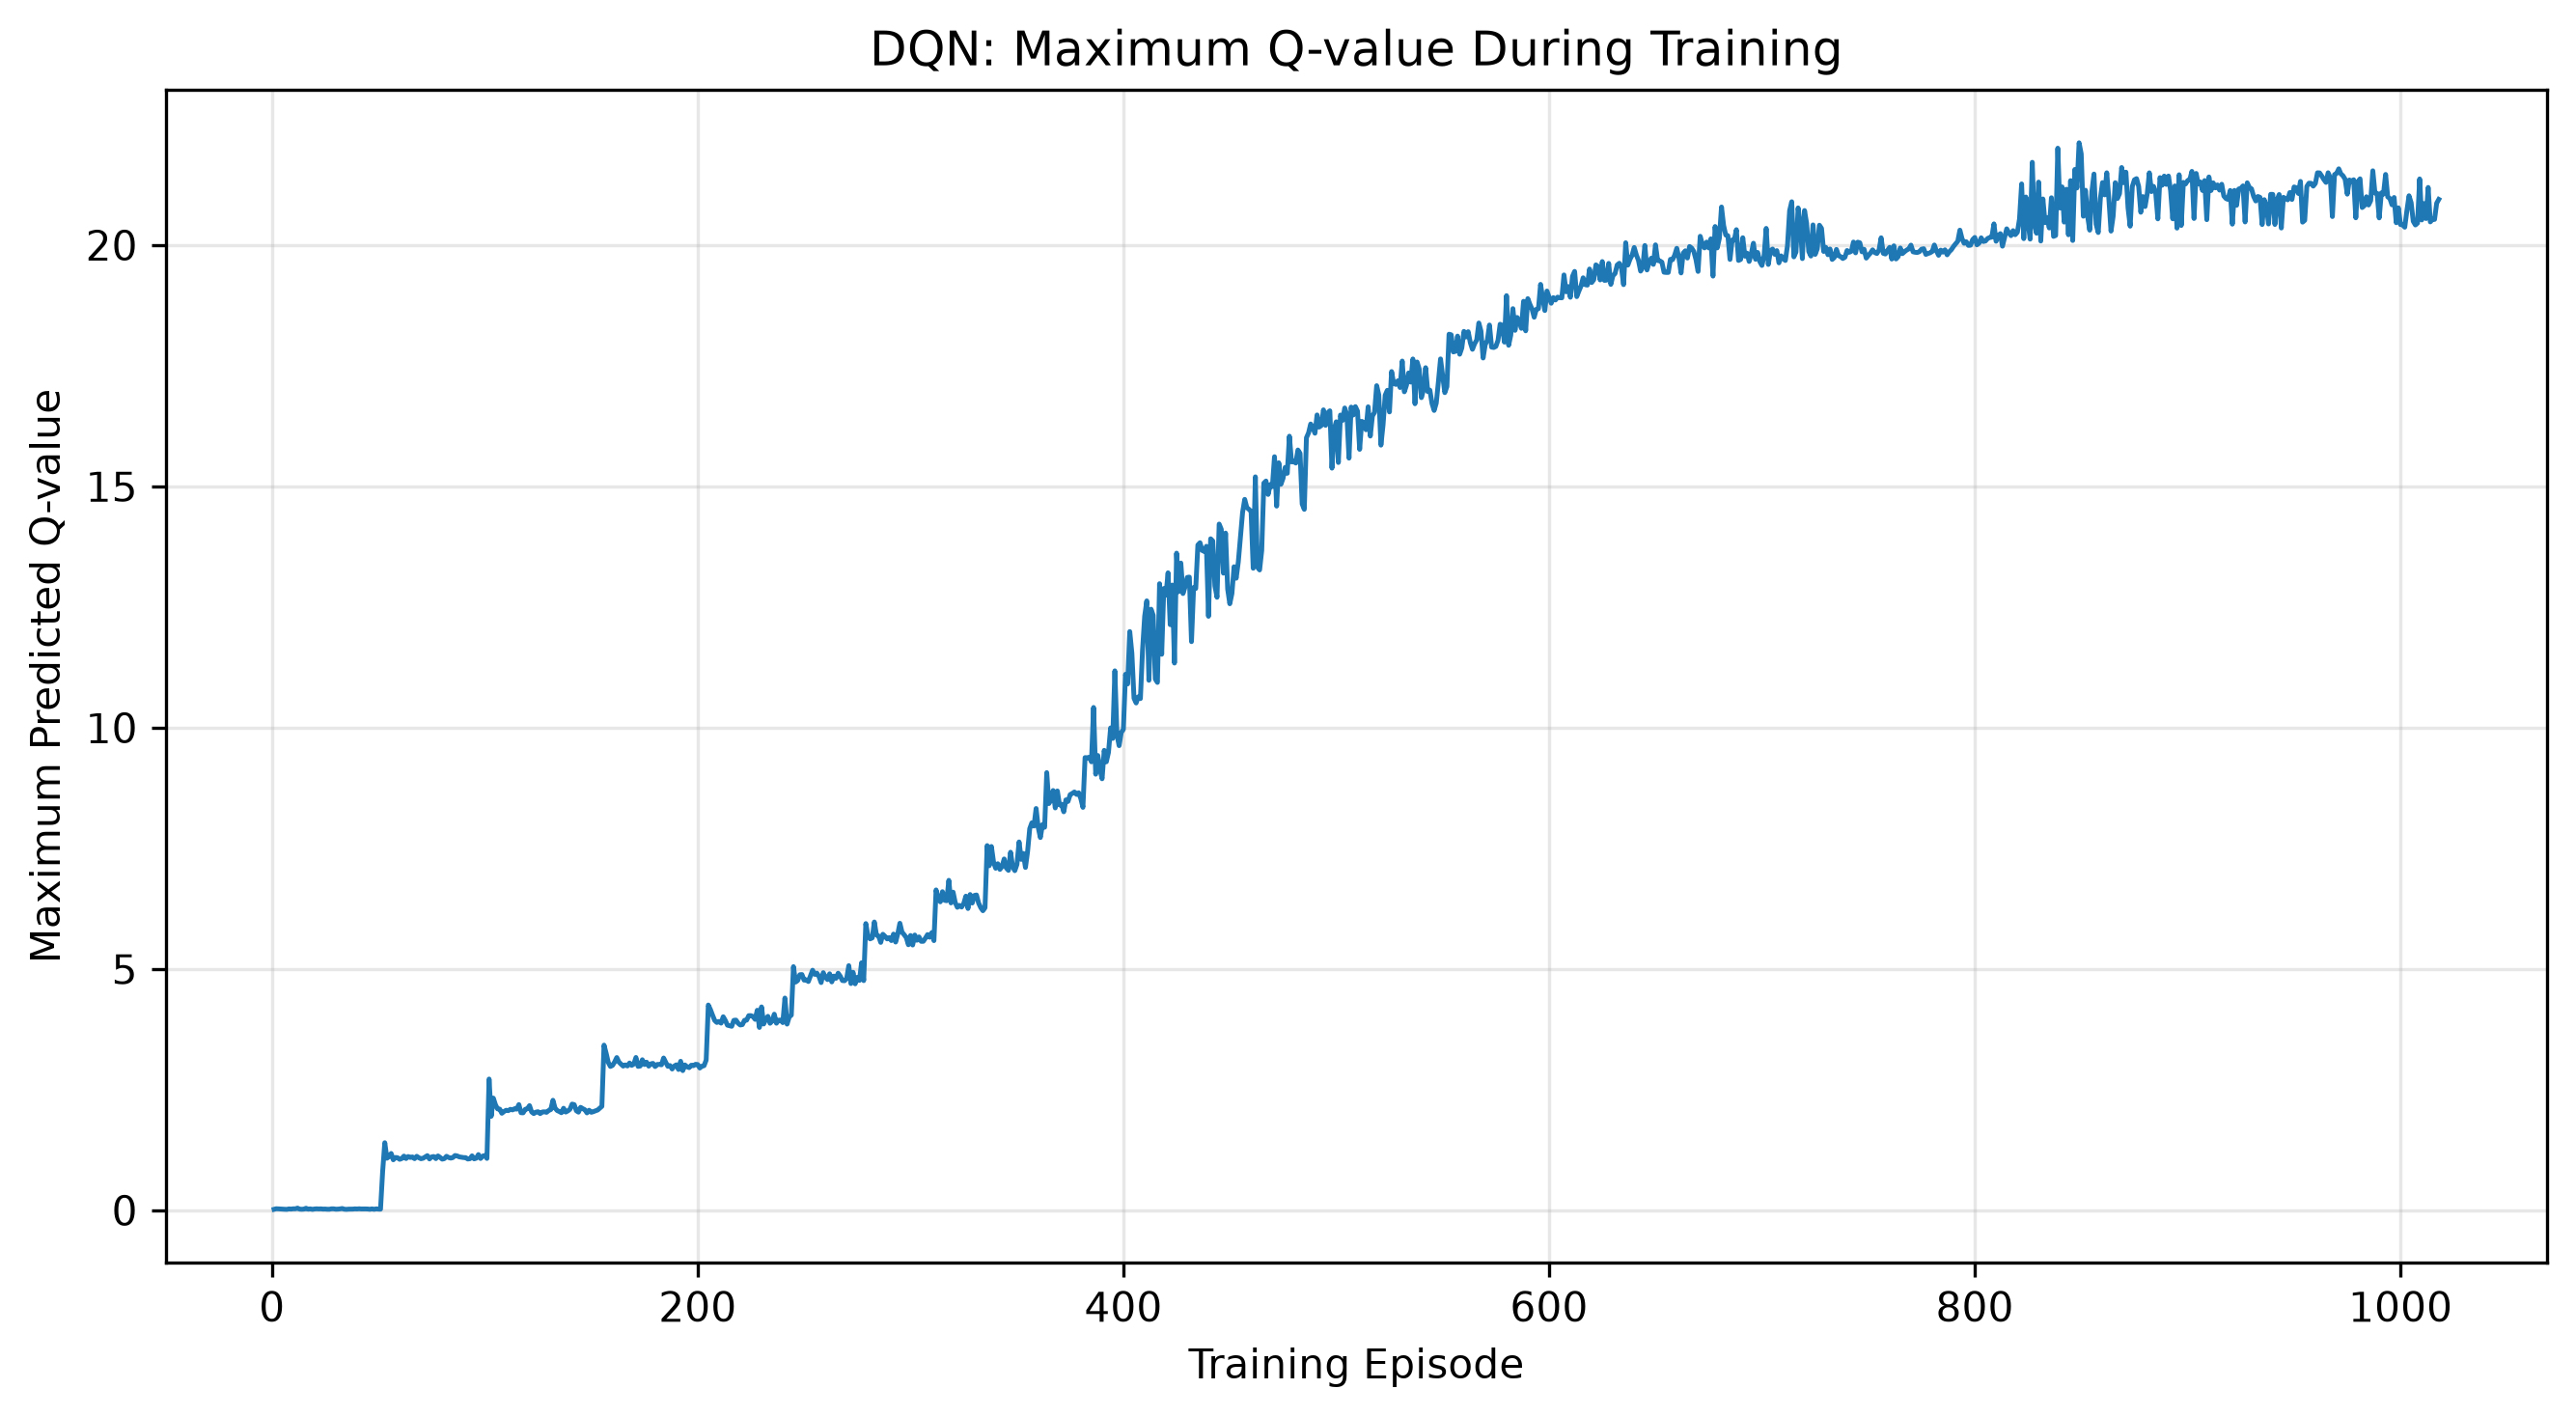

### Figure 2: Episode Rewards and 100-Episode Moving Average

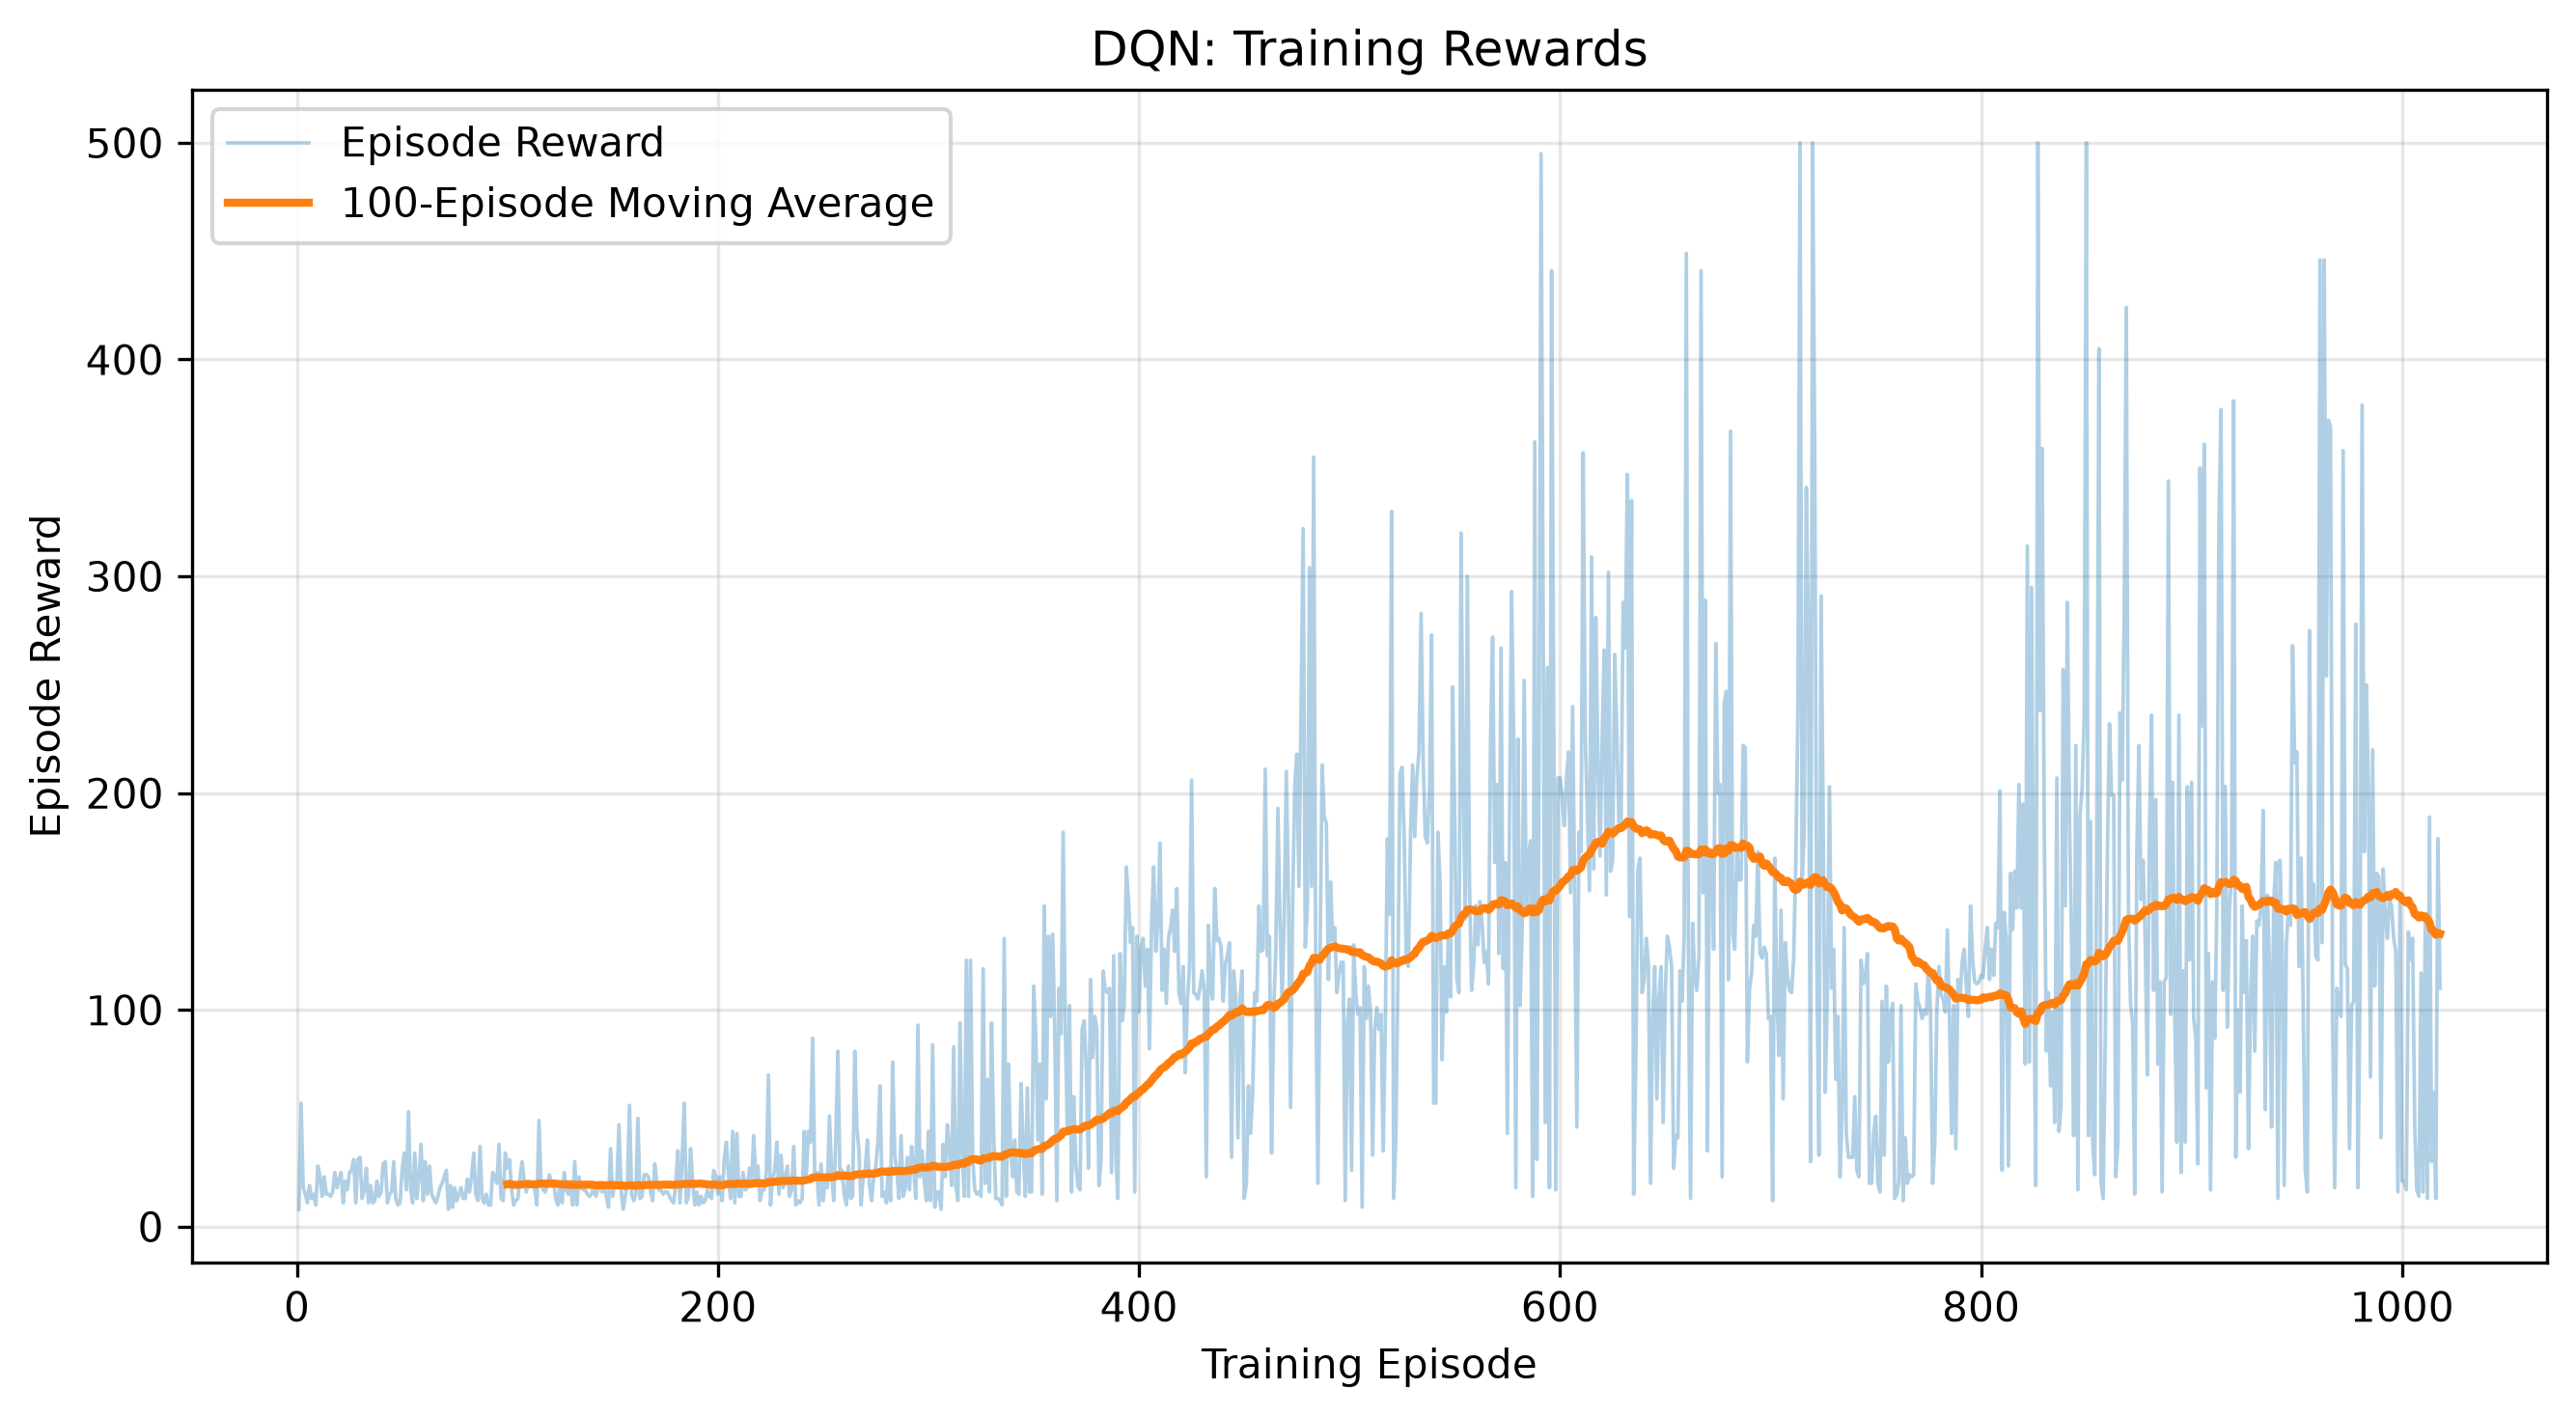

### Figure 3: Reward Histogram over 500 Evaluation Episodes

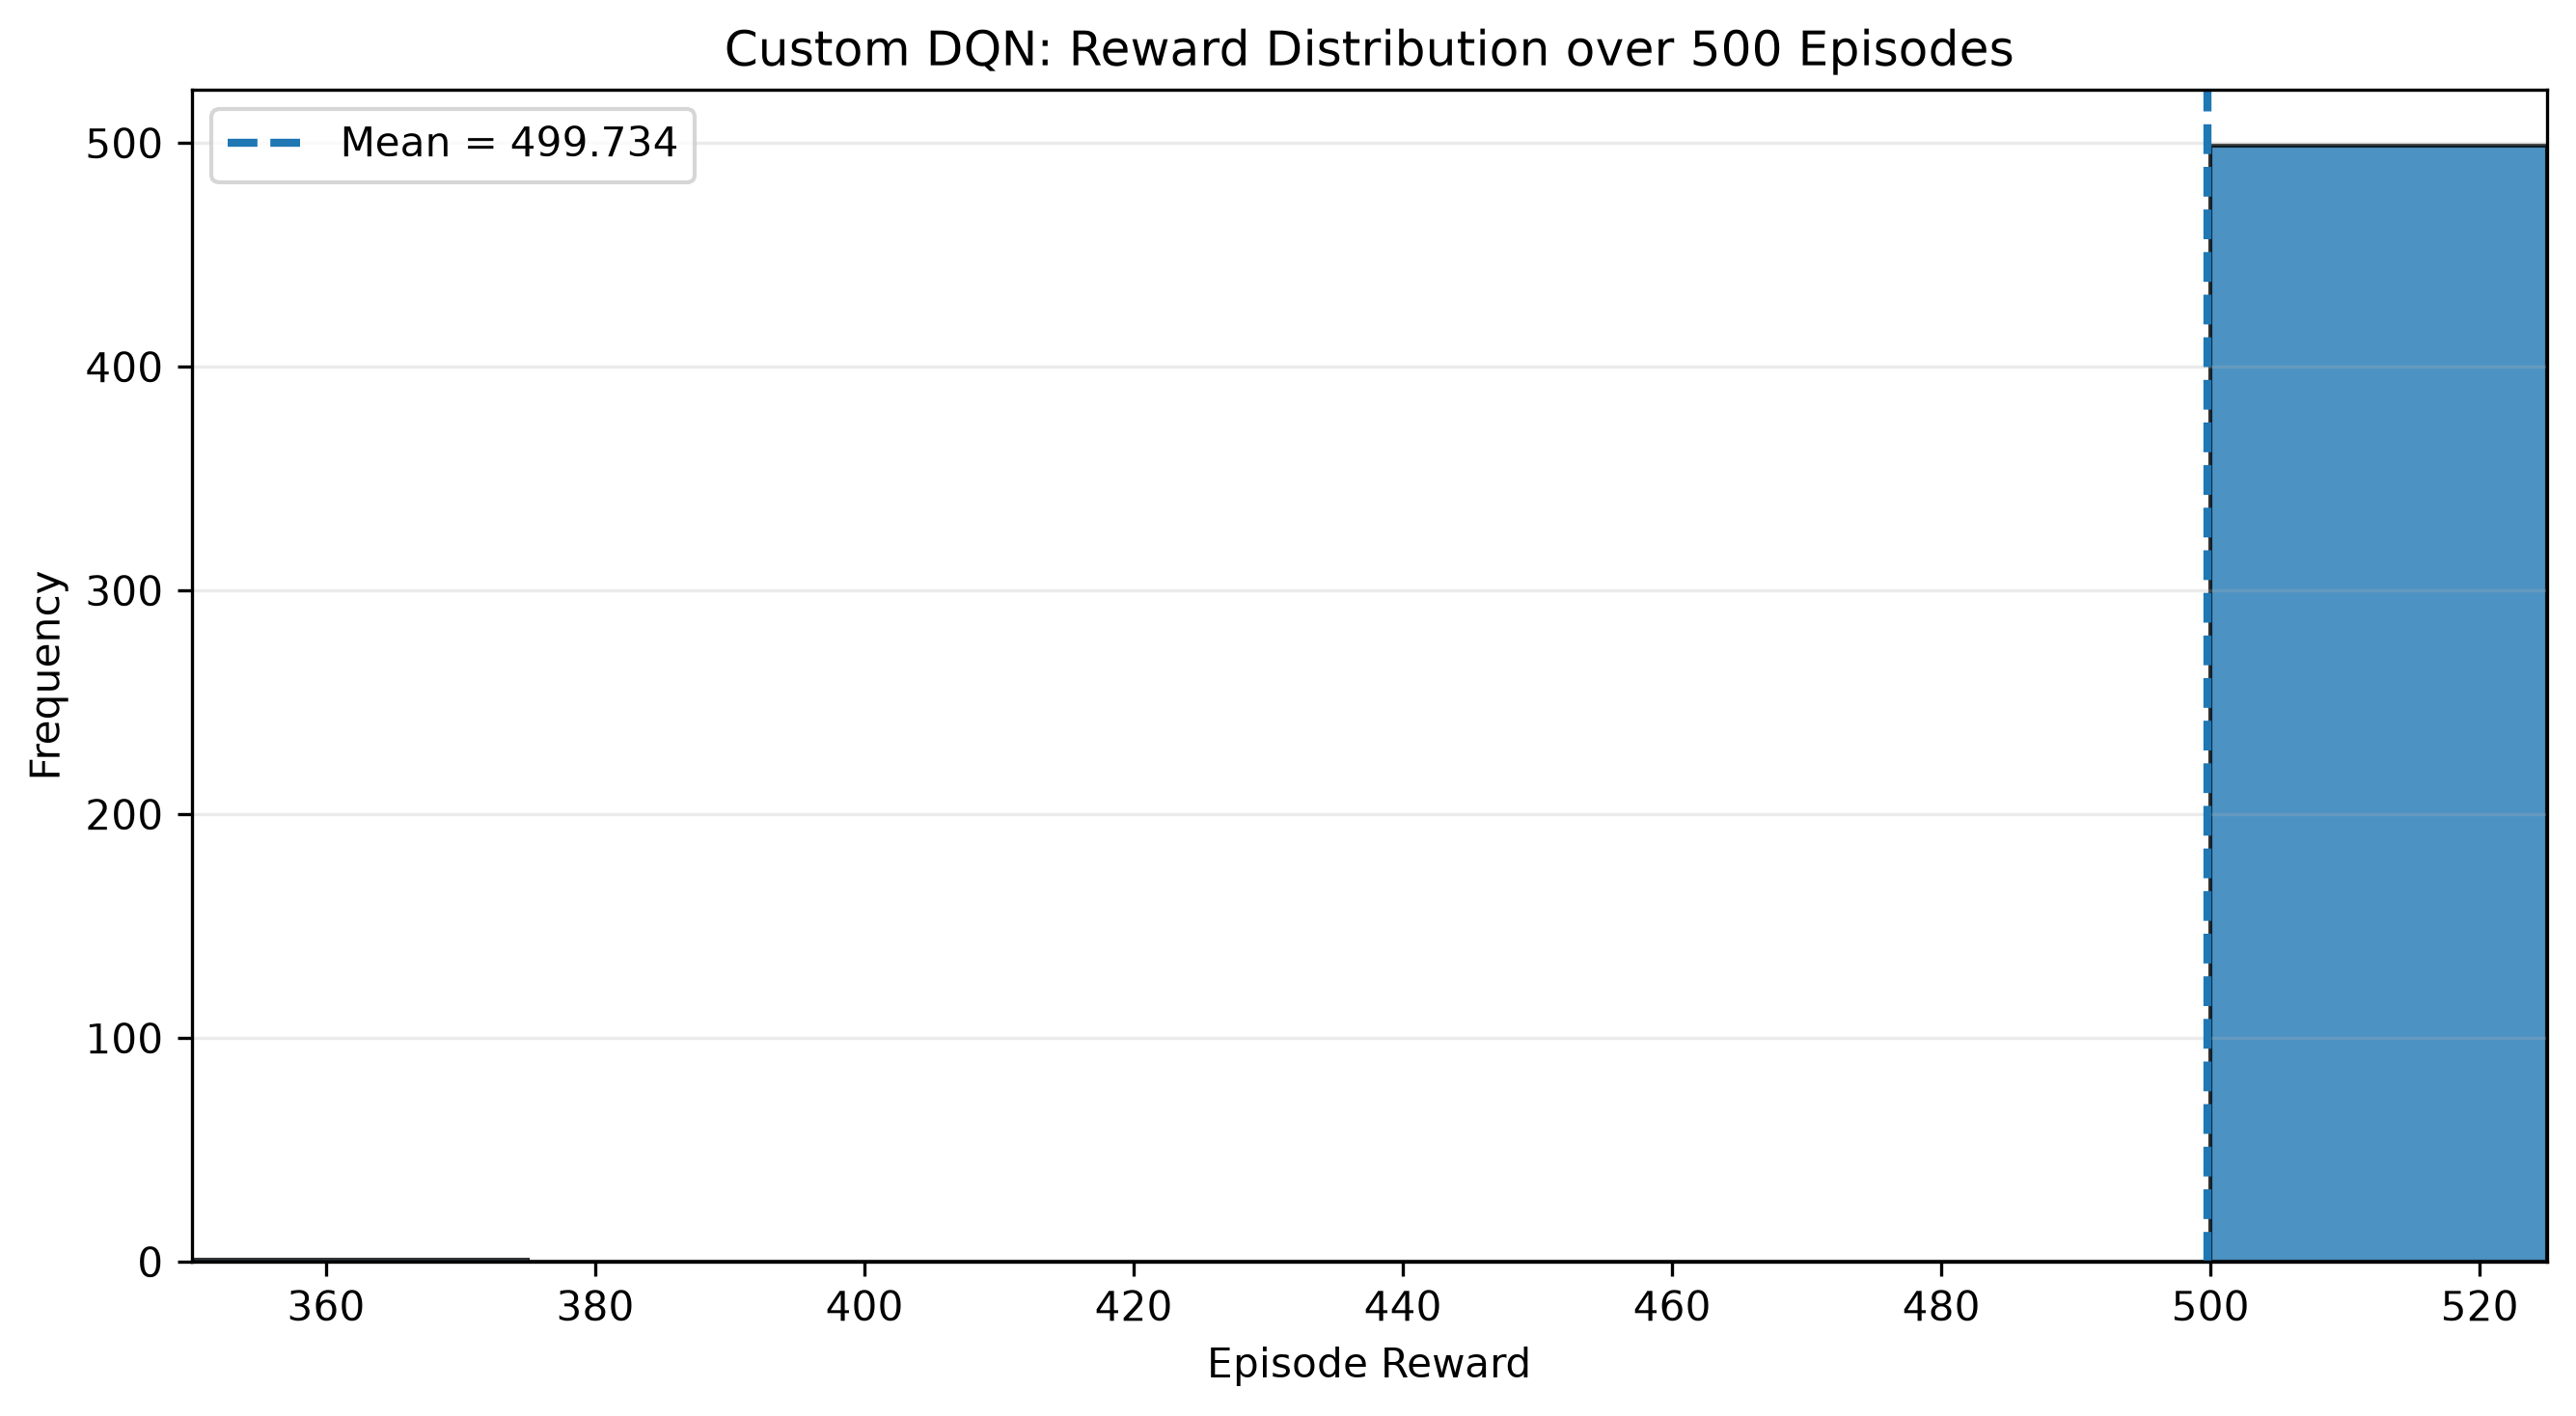

### Figure 4: Greedy Validation Performance

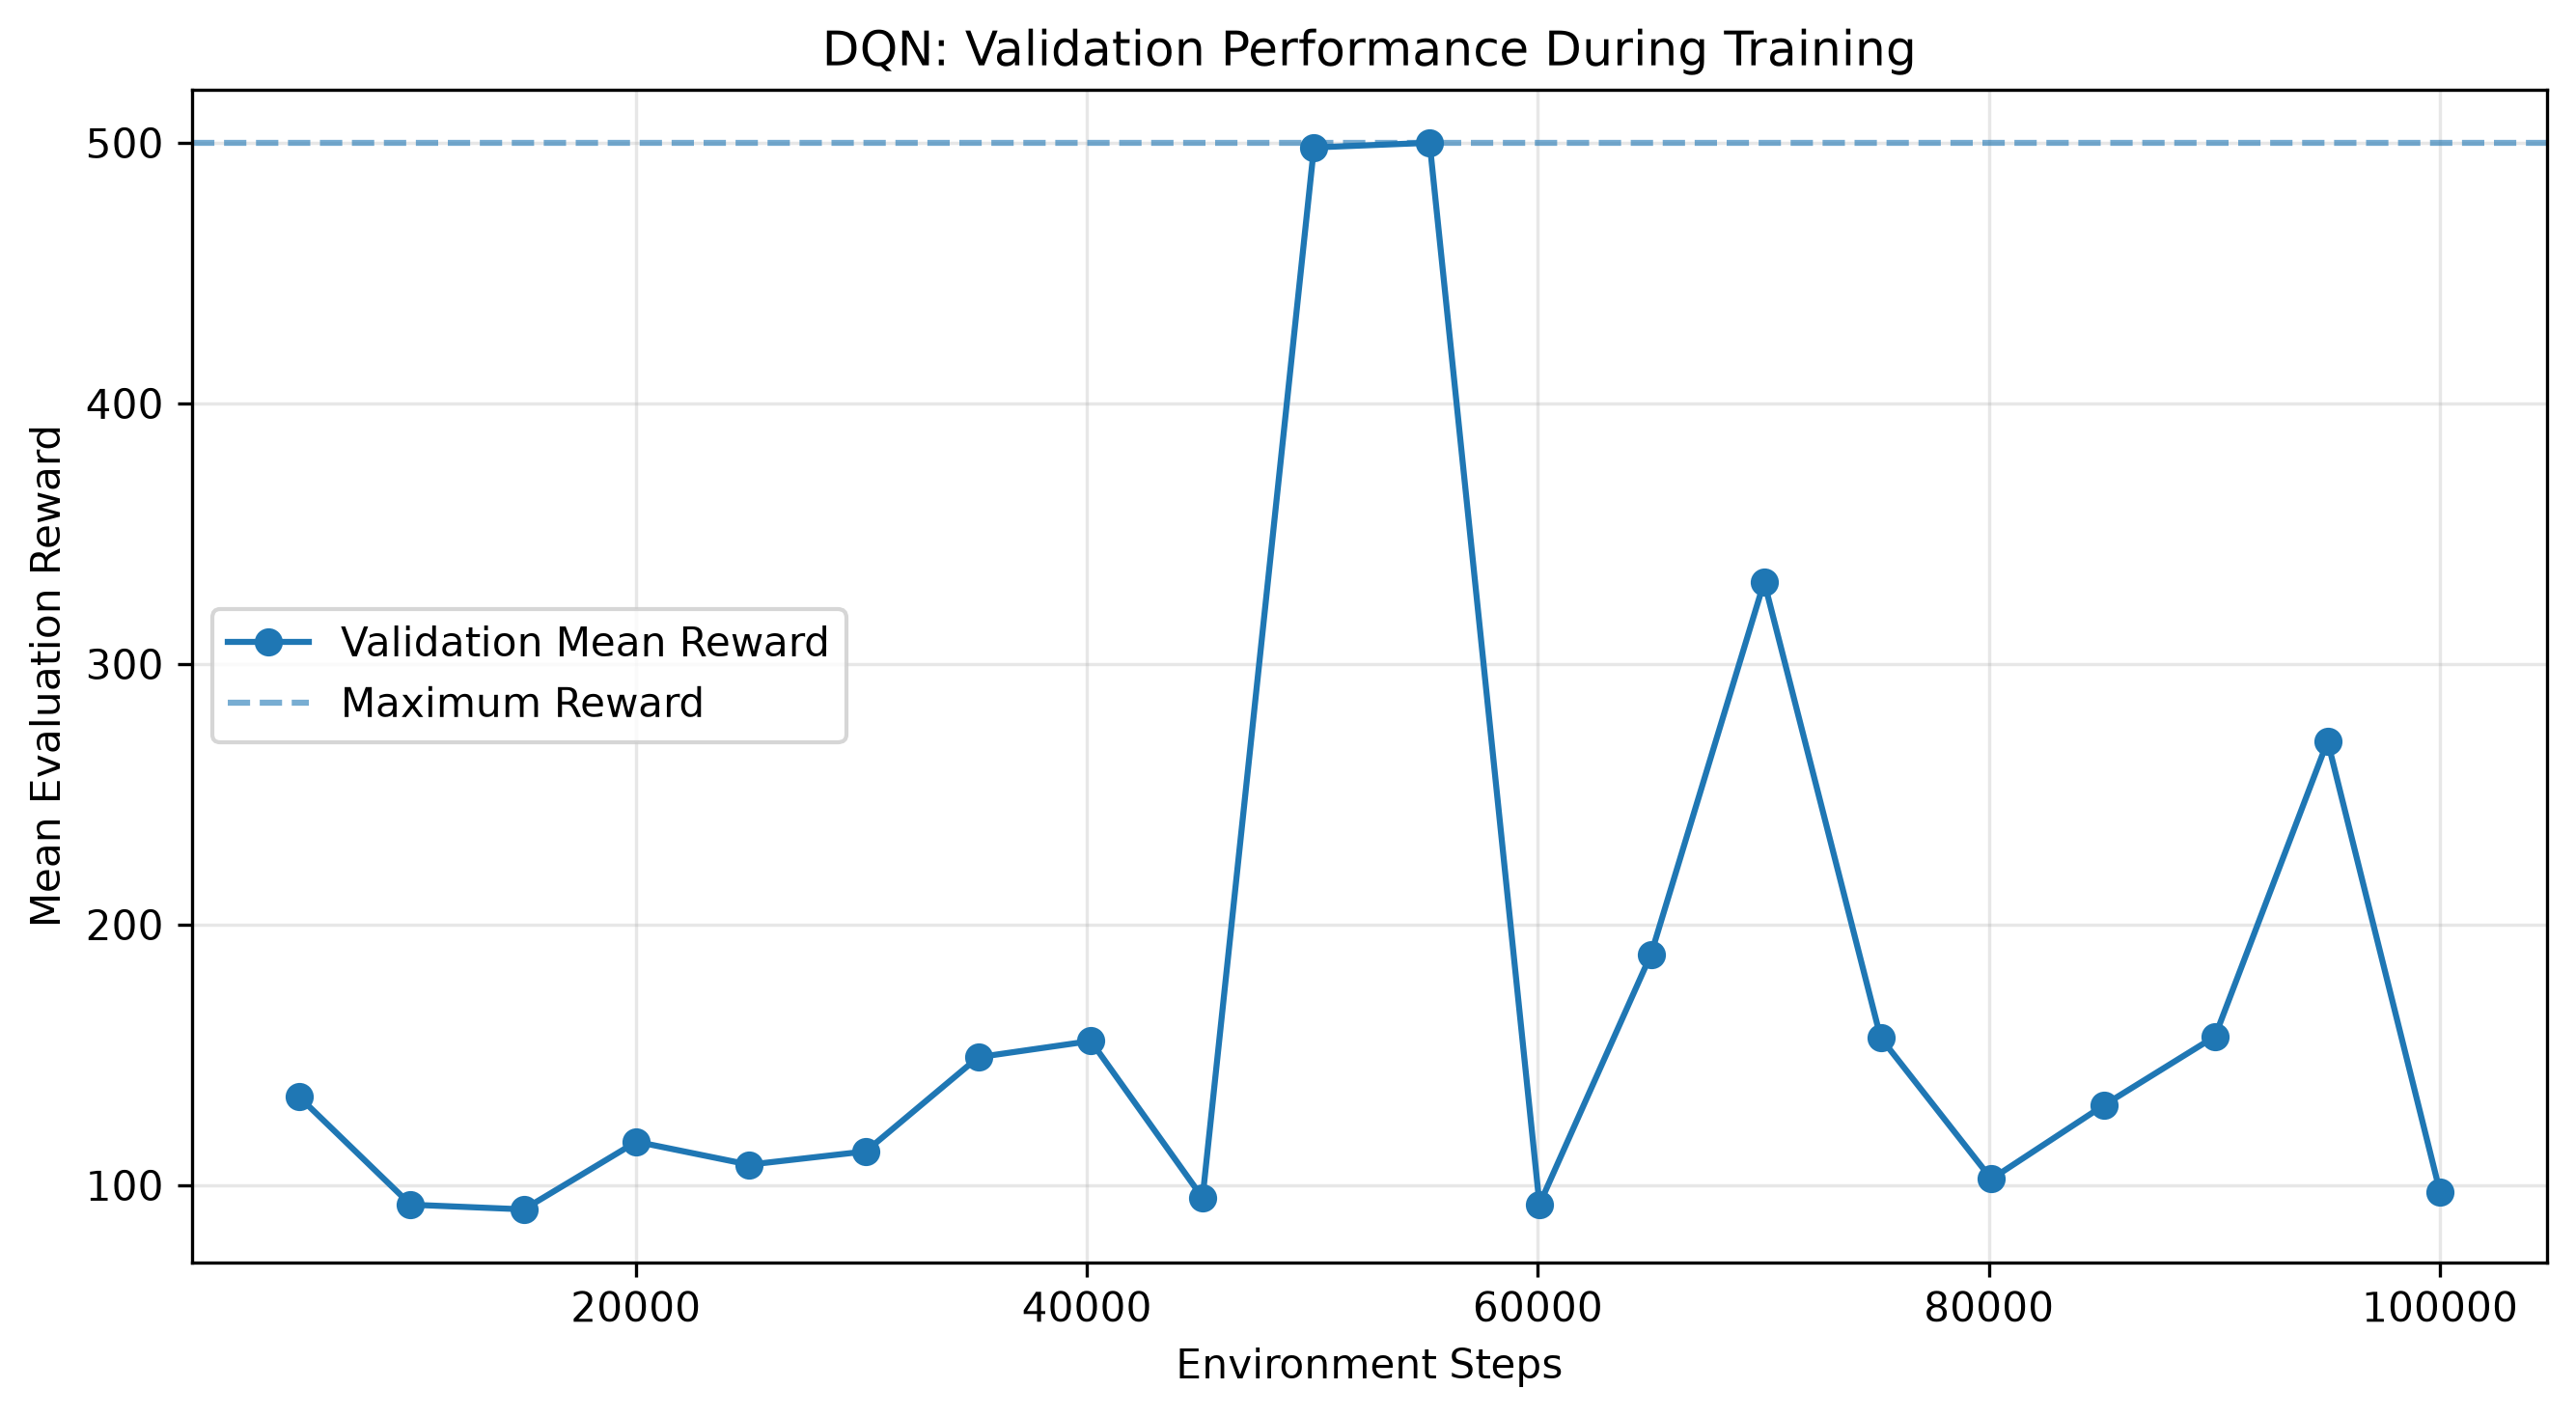

All available figures displayed.


In [5]:

# ============================================================
# Step 10: Display Saved DQN Figures in Jupyter
# No retraining, evaluation, or Matplotlib rendering
# ============================================================

from pathlib import Path
from IPython.display import display, Image, Markdown

RESULTS_DIR = Path("results_cartpole_dqn")

figures = [
    (
        "Figure 1: Maximum Q-values During Training",
        "dqn_max_q.png"
    ),
    (
        "Figure 2: Episode Rewards and 100-Episode Moving Average",
        "dqn_training_rewards.png"
    ),
    (
        "Figure 3: Reward Histogram over 500 Evaluation Episodes",
        "dqn_test_500_histogram.png"
    ),
    (
        "Figure 4: Greedy Validation Performance",
        "dqn_validation.png"
    )
]

for title, filename in figures:

    image_path = RESULTS_DIR / filename

    if not image_path.exists():
        print(f"Missing: {image_path}")
        continue

    display(Markdown(f"### {title}"))

    display(
        Image(
            filename=str(image_path),
            width=800
        )
    )

print("All available figures displayed.")



## Step 11: Edge Cases and Robustness Analysis

### 11.1 Objective

Identify important edge cases in the CartPole-v1 DQN problem and examine how our implementation handles them.

We focus on reinforcement-learning-specific issues rather than basic input validation or software debugging.

### 11.2 Early Environment Termination

An episode may terminate before the 500-step horizon because the pole angle or cart position exceeds the environment's allowed limits.

When a transition leads to a true terminal state, no future reward should be included in the Bellman target.

For a terminal transition,

\[
y_t=r_t.
\]

Our replay buffer stores the `terminated` indicator, and the DQN target is computed as

\[
y_t=r_t+\gamma(1-d_t)
\max_{a'}Q_{\theta^-}(s_{t+1},a'),
\]

where \(d_t=1\) for a true termination.

This prevents the algorithm from incorrectly bootstrapping beyond a terminal state.

### 11.3 Time-Limit Truncation

CartPole-v1 imposes a maximum episode horizon of 500 steps.

Reaching this horizon produces a time-limit truncation rather than necessarily indicating a physical failure.

Our implementation distinguishes `terminated` from `truncated`:

- Both conditions end the current episode.
- Only true termination disables Bellman bootstrapping.
- Reaching 500 steps counts as a successful evaluation episode.

This distinction is important because treating every time-limit truncation as a terminal failure changes the learning target.

### 11.4 Excessive Exploration

An agent may learn a strong greedy policy while obtaining relatively low rewards during training because random exploratory actions can destabilize the pole.

We address this by linearly reducing epsilon from 1.0 to 0.05 during the first 15,000 environment steps.

During independent evaluation, epsilon is set to zero.

Consequently, exploratory training rewards and greedy evaluation rewards measure different behaviors and should be interpreted separately.

### 11.5 Q-Value Overestimation

With a reward of +1 per step and discount factor \(\gamma=0.95\), the maximum possible discounted return is bounded by

\[
Q^*(s,a)\leq
\sum_{k=0}^{\infty}\gamma^k
=
\frac{1}{1-\gamma}
=20.
\]

However, an unconstrained neural network can predict Q-values above this theoretical return bound.

Such predictions are indicators of possible approximation error or overestimation, but do not by themselves prove an implementation bug.

We monitor maximum predicted Q-values throughout training and use a target network, Huber loss, and gradient clipping to improve optimization stability.

These mechanisms do not guarantee the elimination of Q-value overestimation.

### 11.6 Training-Budget Interruption

Training was limited to 100,000 environment interactions.

The training loop can stop when this budget is reached, even if the current episode has not naturally terminated.

A budget-interrupted episode should not be interpreted as an environmental failure.

Our analysis therefore distinguishes the global training-step budget from the environment's termination and truncation conditions.

### 11.7 Empirical Robustness Evidence

The best checkpoint was independently evaluated over 500 episodes.

The recorded results were:

- Mean reward: 499.734
- Sample standard deviation: 5.948
- Success rate: 99.8%
- Successful episodes: 499 out of 500
- Minimum reward: 367

These observations show that the selected checkpoint handles nearly all tested initial conditions successfully.

However, they do not establish correctness for every possible initial condition or guarantee stable convergence during continued training.

The following cell quantitatively examines the saved episode outcomes, Q-value predictions, and representative Bellman-target edge cases without retraining the agent.


In [13]:

# ============================================================
# Step 11: Edge Cases and Robustness Analysis
#
# No training, environment interaction, or model inference.
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Load Saved Experimental Data
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

train_df = pd.read_csv(
    RESULTS_DIR / "training_history.csv"
)

validation_df = pd.read_csv(
    RESULTS_DIR / "validation_history.csv"
)

test_df = pd.read_csv(
    RESULTS_DIR / "dqn_test_500_rewards.csv"
)

GAMMA = 0.95
MAX_EPISODE_STEPS = 500
TRAINING_BUDGET = 100000

print("=" * 60)
print("STEP 11: DQN EDGE-CASE ANALYSIS")
print("=" * 60)


# ------------------------------------------------------------
# 2. Edge Case A: Early Termination
# ------------------------------------------------------------

failed_episodes = test_df[
    test_df["episode_steps"] < MAX_EPISODE_STEPS
]

successful_episodes = test_df[
    test_df["episode_steps"] == MAX_EPISODE_STEPS
]

print("\n[Edge Case A] Early Episode Termination")

print("Successful episodes:", len(successful_episodes))
print("Early-ending episodes:", len(failed_episodes))

if not failed_episodes.empty:

    print("\nEarly-ending episode details:")

    print(
        failed_episodes[
            ["episode", "seed", "reward", "episode_steps"]
        ].to_string(index=False)
    )


# ------------------------------------------------------------
# 3. Edge Case B: Terminal vs Truncated Transitions
# ------------------------------------------------------------

# Controlled theoretical Bellman-target examples.
# These verify expected target behavior, not a new
# execution of the neural-network training function.

reward = 1.0
next_q_values = np.array([6.0, 8.0])

next_q_max = float(np.max(next_q_values))

def bellman_target(reward, next_q_max, terminated):

    return (
        reward
        + GAMMA * (1.0 - float(terminated))
        * next_q_max
    )


normal_target = bellman_target(
    reward, next_q_max, terminated=False
)

terminal_target = bellman_target(
    reward, next_q_max, terminated=True
)

truncated_target = bellman_target(
    reward, next_q_max, terminated=False
)

assert np.isclose(normal_target, 8.6)
assert np.isclose(terminal_target, 1.0)
assert np.isclose(truncated_target, 8.6)

print("\n[Edge Case B] Bellman Target Behavior")

print(f"Normal transition target: {normal_target:.3f}")
print(f"Terminal transition target: {terminal_target:.3f}")
print(f"Time-limit truncation target: {truncated_target:.3f}")

print("Controlled Bellman-target checks passed.")


# ------------------------------------------------------------
# 4. Edge Case C: Exploration and Evaluation
# ------------------------------------------------------------

training_epsilon = float(
    train_df["epsilon"].iloc[-1]
)

print("\n[Edge Case C] Exploration Policy")

print(f"Final training epsilon: {training_epsilon:.3f}")
print("Evaluation epsilon: 0.000")

print(
    "Final 100 training episodes mean reward:",
    round(
        train_df["reward"].tail(100).mean(),
        3
    )
)

print(
    "Independent greedy evaluation mean reward:",
    round(test_df["reward"].mean(), 3)
)

# The two means are descriptive quantities from
# different policies, not a controlled causal test.


# ------------------------------------------------------------
# 5. Edge Case D: Q-Value Overestimation
# ------------------------------------------------------------

theoretical_q_bound = 1.0 / (1.0 - GAMMA)

q_values = train_df[
    "max_q_value"
].to_numpy(dtype=float)

above_bound = q_values > theoretical_q_bound

print("\n[Edge Case D] Q-Value Monitoring")

print(
    f"Theoretical discounted-return bound: "
    f"{theoretical_q_bound:.3f}"
)

print(
    f"Maximum recorded predicted Q-value: "
    f"{q_values.max():.3f}"
)

print(
    "Episodes with recorded MaxQ > 20:",
    int(np.sum(above_bound))
)

print(
    "Fraction of recorded episodes with MaxQ > 20:",
    f"{np.mean(above_bound):.2%}"
)

print(
    "Note: Q-values above the bound indicate "
    "prediction error, not necessarily a code bug."
)


# ------------------------------------------------------------
# 6. Edge Case E: Training Budget Boundary
# ------------------------------------------------------------

last_training_record = train_df.iloc[-1]

last_total_steps = int(
    last_training_record["total_steps"]
)

last_episode_steps = int(
    last_training_record["episode_steps"]
)

print("\n[Edge Case E] Training Budget Boundary")

print("Training budget:", TRAINING_BUDGET)
print("Final total steps:", last_total_steps)
print("Last recorded episode length:", last_episode_steps)

if last_total_steps == TRAINING_BUDGET:

    print(
        "Training reached the specified step budget."
    )

    print(
        "The saved history does not contain enough "
        "terminal-status information to determine "
        "whether the last episode ended naturally "
        "or was interrupted by the budget."
    )


# ------------------------------------------------------------
# 7. Save Edge-Case Summary
# ------------------------------------------------------------

summary = {
    "gamma": GAMMA,
    "evaluation_episodes": int(len(test_df)),
    "successful_episodes": int(
        len(successful_episodes)
    ),
    "early_ending_episodes": int(
        len(failed_episodes)
    ),
    "minimum_episode_reward": float(
        test_df["reward"].min()
    ),
    "normal_bellman_target": normal_target,
    "terminal_bellman_target": terminal_target,
    "truncated_bellman_target": truncated_target,
    "final_training_epsilon": training_epsilon,
    "evaluation_epsilon": 0.0,
    "theoretical_q_bound": theoretical_q_bound,
    "maximum_predicted_q": float(
        q_values.max()
    ),
    "episodes_with_q_above_bound": int(
        np.sum(above_bound)
    ),
    "training_budget_reached": bool(
        last_total_steps == TRAINING_BUDGET
    ),
    "last_episode_boundary_status": "unknown"
}

output_path = RESULTS_DIR / "edge_case_summary.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 60)
print("EDGE-CASE ANALYSIS COMPLETED")
print("=" * 60)

print("Saved summary:", output_path)
print("No training or evaluation was rerun.")


STEP 11: DQN EDGE-CASE ANALYSIS

[Edge Case A] Early Episode Termination
Successful episodes: 499
Early-ending episodes: 1

Early-ending episode details:
 episode   seed  reward  episode_steps
     199 300198   367.0            367

[Edge Case B] Bellman Target Behavior
Normal transition target: 8.600
Terminal transition target: 1.000
Time-limit truncation target: 8.600
Controlled Bellman-target checks passed.

[Edge Case C] Exploration Policy
Final training epsilon: 0.050
Evaluation epsilon: 0.000
Final 100 training episodes mean reward: 135.15
Independent greedy evaluation mean reward: 499.734

[Edge Case D] Q-Value Monitoring
Theoretical discounted-return bound: 20.000
Maximum recorded predicted Q-value: 22.121
Episodes with recorded MaxQ > 20: 258
Fraction of recorded episodes with MaxQ > 20: 25.34%
Note: Q-values above the bound indicate prediction error, not necessarily a code bug.

[Edge Case E] Training Budget Boundary
Training budget: 100000
Final total steps: 100000
Last reco

In [18]:

# ============================================================
# Step 12: Behavioral DQN Validation Experiments
#
# Test A: Deterministic first-10-step trace
# Test B: Exploration-rate ablation
# Test C: Best vs. final checkpoint
#
# No training, no CUDA, no plotting.
# Run repeatedly: 10 seeds (40 episodes) per execution.
# ============================================================

import os
import json
from pathlib import Path

import gymnasium as gym
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

BEST_PATH = RESULTS_DIR / "dqn_best.pt"
FINAL_PATH = RESULTS_DIR / "dqn_final.pt"

OUTPUT_CSV = RESULTS_DIR / "validation_step12_policy_ablation.csv"
TRACE_CSV = RESULTS_DIR / "validation_step12_first10.csv"
SUMMARY_JSON = RESULTS_DIR / "validation_step12_summary.json"

DEVICE = torch.device("cpu")
torch.set_num_threads(1)

SEED_START = 400000
NUM_SEEDS = 40
SEEDS_PER_RUN = 10

POLICIES = [
    "best_greedy",
    "best_epsilon_025",
    "best_random",
    "final_greedy"
]


# ------------------------------------------------------------
# 2. Reconstruct Original Q-Network
# ------------------------------------------------------------

class QNetwork(nn.Module):

    def __init__(
        self,
        state_dim=4,
        action_dim=2,
        hidden_dim=128
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)


def load_model(path):

    network = QNetwork().to(DEVICE)

    network.load_state_dict(
        torch.load(
            path,
            map_location=DEVICE,
            weights_only=True
        )
    )

    network.eval()

    return network


best_model = load_model(BEST_PATH)
final_model = load_model(FINAL_PATH)

print("Best and final DQN checkpoints loaded.")


# ------------------------------------------------------------
# 3. Controlled Episode Rollout
# ------------------------------------------------------------

def run_episode(env, network, seed, epsilon=0.0,
                record_trace=False, max_trace_steps=10):

    state, _ = env.reset(seed=int(seed))

    # Independent, reproducible exploration RNG.
    rng = np.random.default_rng(int(seed) + 12345)

    total_reward = 0.0
    steps = 0
    trace = []

    terminated = False
    truncated = False

    while not (terminated or truncated):

        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.inference_mode():

            q_values = network(state_tensor).squeeze(0)

            q_left = float(q_values[0].item())
            q_right = float(q_values[1].item())

            greedy_action = int(
                q_values.argmax().item()
            )

        if rng.random() < epsilon:

            action = int(rng.integers(0, 2))

        else:

            action = greedy_action

        next_state, reward, terminated, truncated, _ = (
            env.step(action)
        )

        steps += 1
        total_reward += float(reward)

        if record_trace and steps <= max_trace_steps:

            trace.append({
                "step": steps,
                "cart_position": float(state[0]),
                "cart_velocity": float(state[1]),
                "pole_angle": float(state[2]),
                "pole_angular_velocity": float(state[3]),
                "q_left": q_left,
                "q_right": q_right,
                "greedy_action": greedy_action,
                "selected_action": action,
                "reward": float(reward),
                "terminated": bool(terminated),
                "truncated": bool(truncated)
            })

        state = next_state

    return {
        "reward": total_reward,
        "steps": steps,
        "success": int(steps == 500),
        "trace": trace
    }


# ------------------------------------------------------------
# 4. Test A: First-10-Step Reproducibility
# ------------------------------------------------------------

trace_seed = 420000

if not TRACE_CSV.exists():

    trace_env = gym.make("CartPole-v1")

    try:

        first = run_episode(
            trace_env,
            best_model,
            seed=trace_seed,
            epsilon=0.0,
            record_trace=True
        )

        second = run_episode(
            trace_env,
            best_model,
            seed=trace_seed,
            epsilon=0.0,
            record_trace=True
        )

    finally:
        trace_env.close()

    trace_df = pd.DataFrame(first["trace"])
    repeated_df = pd.DataFrame(second["trace"])

    reproducible = trace_df.equals(repeated_df)

    action_consistent = bool(
        (
            trace_df["selected_action"]
            == trace_df["greedy_action"]
        ).all()
    )

    print("\nTEST A: DETERMINISTIC REPRODUCIBILITY")

    print("Identical repeated trajectories:", reproducible)
    print("All actions agree with argmax Q:", action_consistent)

    print("\nFirst 10 Steps:")

    print(
        trace_df[
            [
                "step",
                "pole_angle",
                "pole_angular_velocity",
                "q_left",
                "q_right",
                "selected_action",
                "reward"
            ]
        ].round(4).to_string(index=False)
    )

    if not reproducible:
        raise AssertionError(
            "Repeated deterministic rollouts differ."
        )

    if not action_consistent:
        raise AssertionError(
            "Greedy action does not match argmax Q."
        )

    trace_df.to_csv(TRACE_CSV, index=False)

else:

    print("\nTEST A already completed.")
    print("Existing first-10-step trace preserved.")


# ------------------------------------------------------------
# 5. Restore Existing Policy-Ablation Results
# ------------------------------------------------------------

if OUTPUT_CSV.exists():

    records = pd.read_csv(OUTPUT_CSV).to_dict("records")

else:

    records = []

completed_pairs = {
    (int(record["seed"]), record["policy"])
    for record in records
}

if len(completed_pairs) != len(records):
    raise ValueError("Duplicate seed-policy results found.")

all_seeds = list(
    range(SEED_START, SEED_START + NUM_SEEDS)
)

pending_seeds = [
    seed
    for seed in all_seeds
    if any(
        (seed, policy) not in completed_pairs
        for policy in POLICIES
    )
]

seeds_this_run = pending_seeds[:SEEDS_PER_RUN]


# ------------------------------------------------------------
# 6. Tests B and C: Controlled Policy Comparisons
# ------------------------------------------------------------

policy_settings = {
    "best_greedy": (best_model, 0.0),
    "best_epsilon_025": (best_model, 0.25),
    "best_random": (best_model, 1.0),
    "final_greedy": (final_model, 0.0)
}

print("\nTESTS B AND C: POLICY COMPARISONS")
print("Device:", DEVICE)
print("Completed evaluations:", len(records), "/ 160")
print("Seeds scheduled this run:", seeds_this_run)

if seeds_this_run:

    env = gym.make("CartPole-v1")

    try:

        for seed in seeds_this_run:

            for policy_name in POLICIES:

                if (seed, policy_name) in completed_pairs:
                    continue

                network, epsilon = policy_settings[
                    policy_name
                ]

                result = run_episode(
                    env,
                    network,
                    seed=seed,
                    epsilon=epsilon
                )

                records.append({
                    "seed": seed,
                    "policy": policy_name,
                    "epsilon": epsilon,
                    "reward": result["reward"],
                    "steps": result["steps"],
                    "success": result["success"]
                })

                completed_pairs.add((seed, policy_name))

                # Save immediately after every episode.
                temp_path = OUTPUT_CSV.with_suffix(".tmp")

                pd.DataFrame(records).to_csv(
                    temp_path,
                    index=False
                )

                os.replace(temp_path, OUTPUT_CSV)

            print(f"Seed {seed} completed.", flush=True)

    finally:
        env.close()

else:

    print("All validation seeds already completed.")


# ------------------------------------------------------------
# 7. Quantitative Summary
# ------------------------------------------------------------

results_df = pd.DataFrame(records)

print("\n" + "=" * 65)
print("POLICY VALIDATION RESULTS")
print("=" * 65)

summary_rows = []

for policy in POLICIES:

    subset = results_df[
        results_df["policy"] == policy
    ]

    if subset.empty:
        continue

    reward_values = subset["reward"].to_numpy()

    summary_rows.append({
        "policy": policy,
        "episodes": len(subset),
        "mean_reward": float(np.mean(reward_values)),
        "std_reward": (
            float(np.std(reward_values, ddof=1))
            if len(subset) > 1
            else np.nan
        ),
        "success_rate": float(subset["success"].mean()),
        "min_reward": float(np.min(reward_values)),
        "max_reward": float(np.max(reward_values))
    })

summary_df = pd.DataFrame(summary_rows)

print(
    summary_df.round(3).to_string(index=False)
)

print("\nProgress:", len(results_df), "/ 160 episodes")


# ------------------------------------------------------------
# 8. Paired Comparisons After All Seeds Are Completed
# ------------------------------------------------------------

if len(results_df) == NUM_SEEDS * len(POLICIES):

    pivot = results_df.pivot(
        index="seed",
        columns="policy",
        values="reward"
    )

    comparisons = [
        ("best_greedy", "best_epsilon_025"),
        ("best_greedy", "best_random"),
        ("best_greedy", "final_greedy")
    ]

    rng_boot = np.random.default_rng(42)

    paired_results = []

    print("\nPAIRED POLICY COMPARISONS")
    print("(Positive difference favors best_greedy.)")

    for policy_a, policy_b in comparisons:

        differences = (
            pivot[policy_a] - pivot[policy_b]
        ).to_numpy()

        bootstrap_means = np.array([
            rng_boot.choice(
                differences,
                size=len(differences),
                replace=True
            ).mean()
            for _ in range(2000)
        ])

        ci_low, ci_high = np.percentile(
            bootstrap_means,
            [2.5, 97.5]
        )

        mean_difference = float(differences.mean())

        paired_results.append({
            "policy_a": policy_a,
            "policy_b": policy_b,
            "mean_reward_difference": mean_difference,
            "bootstrap_ci_95_low": float(ci_low),
            "bootstrap_ci_95_high": float(ci_high)
        })

        print(
            f"{policy_a} vs {policy_b}: "
            f"Difference = {mean_difference:.2f}, "
            f"95% CI = [{ci_low:.2f}, {ci_high:.2f}]"
        )

    summary_data = {
        "seeds": NUM_SEEDS,
        "episodes_per_policy": NUM_SEEDS,
        "policy_statistics": summary_rows,
        "paired_comparisons": paired_results,
        "deterministic_trace_file": str(TRACE_CSV)
    }

    with open(SUMMARY_JSON, "w") as f:
        json.dump(summary_data, f, indent=4)

    print("\nAll validation experiments completed.")
    print("Summary saved:", SUMMARY_JSON)

else:

    print(
        "\nValidation incomplete. "
        "Run this same cell again for the next 10 seeds."
    )

print("\nNo gradient updates or training were performed.")


Best and final DQN checkpoints loaded.

TEST A already completed.
Existing first-10-step trace preserved.

TESTS B AND C: POLICY COMPARISONS
Device: cpu
Completed evaluations: 160 / 160
Seeds scheduled this run: []
All validation seeds already completed.

POLICY VALIDATION RESULTS
          policy  episodes  mean_reward  std_reward  success_rate  min_reward  max_reward
     best_greedy        40      500.000       0.000           1.0       500.0       500.0
best_epsilon_025        40       48.025      45.087           0.0        11.0       212.0
     best_random        40       21.700       8.373           0.0        10.0        41.0
    final_greedy        40      101.800       9.675           0.0        87.0       118.0

Progress: 160 / 160 episodes

PAIRED POLICY COMPARISONS
(Positive difference favors best_greedy.)
best_greedy vs best_epsilon_025: Difference = 451.98, 95% CI = [437.47, 464.63]
best_greedy vs best_random: Difference = 478.30, 95% CI = [475.75, 481.02]
best_greedy vs


## Step 13: Non-standard Visualization — Q-value Action Preference Map

### 13.1 Objective

Standard DQN evaluation plots show training rewards and estimated Q-values over time. However, they do not directly explain how the learned network selects actions in different physical states.

We therefore construct a two-dimensional Q-value action preference map to visualize the learned decision structure.

This is a non-standard visualization designed specifically for the CartPole control problem.

### 13.2 State-Space Analysis

The CartPole observation is

\[
s=(x,\dot{x},\theta,\dot{\theta}),
\]

where \(x\) and \(\dot{x}\) represent cart position and velocity, and \(\theta\) and \(\dot{\theta}\) represent pole angle and angular velocity.

To visualize a two-dimensional slice of the four-dimensional state space, we fix

\[
x=0,\qquad \dot{x}=0
\]

and vary

\[
\theta\in[-0.18,0.18]
\]

and

\[
\dot{\theta}\in[-1.5,1.5].
\]

All angles are measured in radians, and angular velocities in radians per second.

### 13.3 Action Preference

The trained network predicts two action-values:

\[
Q_\theta(s,0),\qquad Q_\theta(s,1).
\]

We define the action preference margin:

\[
\Delta Q(s)=Q_\theta(s,1)-Q_\theta(s,0).
\]

Therefore:

- Positive values indicate a preference for the right action.
- Negative values indicate a preference for the left action.
- Values near zero indicate that the network estimates similar returns for both actions.

The zero contour

\[
\Delta Q(s)=0
\]

represents a decision boundary where the preferred action changes.

### 13.4 Physics-Informed Symmetry Analysis

The CartPole control problem is approximately symmetric under simultaneous reflection of position, velocity, pole angle, angular velocity, and action direction.

For the selected slice with zero cart position and velocity, the optimal action-value difference is expected to satisfy

\[
\Delta Q(-\theta,-\dot{\theta})
=
-\Delta Q(\theta,\dot{\theta})
\]

under symmetric dynamics and an ideal optimal Q-function.

We investigate whether the learned DQN approximately preserves this symmetry.

Two metrics are reported:

1. Mean absolute symmetry error:

\[
E_{\mathrm{sym}}=
\operatorname{Mean}
\left[
|\Delta Q(\theta,\dot{\theta})+
\Delta Q(-\theta,-\dot{\theta})|
\right].
\]

2. Mirrored action agreement: the proportion of reflected state pairs for which the greedy action changes direction.

Because neural-network approximation and finite training do not guarantee exact symmetry, deviations are interpreted as learned-policy approximation effects rather than automatic evidence of implementation errors.

### 13.5 Limitations

The map represents a two-dimensional conditional slice through the full four-dimensional state space.

Some combinations of pole angle and angular velocity may be uncommon under the trained policy.

Therefore, the visualization explains the network's predicted action preferences on this slice, but does not prove that every depicted action is optimal or that the policy performs successfully from all such states.

### 13.6 Experimental Procedure

We load the previously saved best DQN checkpoint and evaluate the network over a grid of states.

No environment interaction, gradient calculation, or retraining is performed.

The results are saved as:

- `dqn_action_preference_map.png`
- `dqn_action_preference_map.pdf`
- `dqn_action_preference_grid.csv`
- `dqn_action_preference_summary.json`

The visualization uses a non-interactive plotting canvas to avoid Jupyter display-backend issues.


In [19]:

# ============================================================
# Step 13: Non-standard Q-value Action Preference Map
#
# - Load the previously trained best checkpoint
# - Evaluate a 2D state-space slice
# - Visualize the Q-value difference Q(right)-Q(left)
# - Examine left-right symmetry
# - Save PNG, PDF, CSV, and JSON
#
# No training, no Gymnasium rollout, no CUDA.
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import TwoSlopeNorm


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = Path("results_cartpole_dqn")

MODEL_PATH = RESULTS_DIR / "dqn_best.pt"

FIG_PNG = RESULTS_DIR / "dqn_action_preference_map.png"
FIG_PDF = RESULTS_DIR / "dqn_action_preference_map.pdf"

GRID_CSV = RESULTS_DIR / "dqn_action_preference_grid.csv"
SUMMARY_JSON = RESULTS_DIR / "dqn_action_preference_summary.json"

DEVICE = torch.device("cpu")
torch.set_num_threads(1)

print("Device:", DEVICE)


# ------------------------------------------------------------
# 2. Reconstruct Original DQN Network
# ------------------------------------------------------------

class QNetwork(nn.Module):

    def __init__(
        self,
        state_dim=4,
        action_dim=2,
        hidden_dim=128
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)


network = QNetwork().to(DEVICE)

network.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

network.eval()

print("Best DQN checkpoint loaded.")


# ------------------------------------------------------------
# 3. Construct a 2D State-Space Grid
# ------------------------------------------------------------

# Fix cart position and cart velocity.
CART_POSITION = 0.0
CART_VELOCITY = 0.0

# Pole angle and angular velocity.
angles = np.linspace(-0.18, 0.18, 121)
angular_velocities = np.linspace(-1.5, 1.5, 151)

angle_grid, velocity_grid = np.meshgrid(
    angles,
    angular_velocities
)

num_states = angle_grid.size

# Each state is:
# [cart_position, cart_velocity,
#  pole_angle, pole_angular_velocity]

states = np.column_stack([
    np.full(num_states, CART_POSITION),
    np.full(num_states, CART_VELOCITY),
    angle_grid.ravel(),
    velocity_grid.ravel()
]).astype(np.float32)

print("Number of grid states:", num_states)


# ------------------------------------------------------------
# 4. Predict Q-values
# ------------------------------------------------------------

state_tensor = torch.as_tensor(
    states,
    dtype=torch.float32,
    device=DEVICE
)

with torch.inference_mode():

    q_values = network(
        state_tensor
    ).cpu().numpy()

q_left = q_values[:, 0]
q_right = q_values[:, 1]

q_gap = q_right - q_left

greedy_actions = np.argmax(
    q_values,
    axis=1
)

# Reshape to the 2D grid.
q_gap_grid = q_gap.reshape(
    angle_grid.shape
)


# ------------------------------------------------------------
# 5. Compute Action-Preference Statistics
# ------------------------------------------------------------

fraction_right = float(
    np.mean(greedy_actions == 1)
)

fraction_left = float(
    np.mean(greedy_actions == 0)
)

max_gap = float(np.max(q_gap))
min_gap = float(np.min(q_gap))

mean_absolute_gap = float(
    np.mean(np.abs(q_gap))
)

print("\nACTION-PREFERENCE STATISTICS")

print(f"Fraction preferring Right: {fraction_right:.2%}")
print(f"Fraction preferring Left:  {fraction_left:.2%}")

print(f"Maximum Q-gap: {max_gap:.4f}")
print(f"Minimum Q-gap: {min_gap:.4f}")

print(
    f"Mean absolute Q-gap: "
    f"{mean_absolute_gap:.4f}"
)


# ------------------------------------------------------------
# 6. Physics-Informed Symmetry Analysis
# ------------------------------------------------------------

# The grids are symmetric around zero.
# Reversing both axes maps (angle, angular velocity)
# to (-angle, -angular velocity).

mirrored_gap = q_gap_grid[::-1, ::-1]

symmetry_error = float(
    np.mean(
        np.abs(q_gap_grid + mirrored_gap)
    )
)

# Ignore nearly tied action predictions when measuring
# whether the preferred action flips under reflection.
MARGIN_THRESHOLD = 0.1

confident_mask = (
    (np.abs(q_gap_grid) > MARGIN_THRESHOLD)
    &
    (np.abs(mirrored_gap) > MARGIN_THRESHOLD)
)

action_flip = (
    (q_gap_grid > 0)
    !=
    (mirrored_gap > 0)
)

if np.any(confident_mask):

    mirrored_action_agreement = float(
        np.mean(
            action_flip[confident_mask]
        )
    )

else:

    mirrored_action_agreement = None

confident_fraction = float(
    np.mean(confident_mask)
)

print("\nPHYSICS-INFORMED SYMMETRY ANALYSIS")

print(
    f"Mean absolute symmetry error: "
    f"{symmetry_error:.4f}"
)

print(
    f"Confident state-pair fraction: "
    f"{confident_fraction:.2%}"
)

if mirrored_action_agreement is not None:

    print(
        f"Mirrored action agreement: "
        f"{mirrored_action_agreement:.2%}"
    )

else:

    print(
        "Mirrored action agreement: undefined "
        "(no sufficiently confident pairs)."
    )


# ------------------------------------------------------------
# 7. Save Grid Data
# ------------------------------------------------------------

grid_df = pd.DataFrame({
    "cart_position": states[:, 0],
    "cart_velocity": states[:, 1],
    "pole_angle": states[:, 2],
    "pole_angular_velocity": states[:, 3],
    "q_left": q_left,
    "q_right": q_right,
    "q_gap": q_gap,
    "greedy_action": greedy_actions
})

grid_df.to_csv(
    GRID_CSV,
    index=False
)

summary = {
    "model": "Custom DQN Best Checkpoint",
    "cart_position": CART_POSITION,
    "cart_velocity": CART_VELOCITY,
    "num_grid_states": int(num_states),
    "angle_range": [-0.18, 0.18],
    "angular_velocity_range": [-1.5, 1.5],
    "fraction_right": fraction_right,
    "fraction_left": fraction_left,
    "maximum_q_gap": max_gap,
    "minimum_q_gap": min_gap,
    "mean_absolute_q_gap": mean_absolute_gap,
    "mean_absolute_symmetry_error": symmetry_error,
    "confident_pair_fraction": confident_fraction,
    "mirrored_action_agreement": mirrored_action_agreement,
    "symmetry_margin_threshold": MARGIN_THRESHOLD
}

with open(SUMMARY_JSON, "w") as f:
    json.dump(summary, f, indent=4)


# ------------------------------------------------------------
# 8. Generate Non-standard Visualization
# ------------------------------------------------------------

fig = Figure(figsize=(9, 6))
FigureCanvasAgg(fig)

ax = fig.add_subplot(111)

abs_max = max(
    float(np.max(np.abs(q_gap_grid))),
    1e-6
)

norm = TwoSlopeNorm(
    vmin=-abs_max,
    vcenter=0,
    vmax=abs_max
)

heatmap = ax.pcolormesh(
    angle_grid,
    velocity_grid,
    q_gap_grid,
    shading="auto",
    cmap="coolwarm",
    norm=norm,
    rasterized=True
)

# Draw decision boundary where Q(right) = Q(left).
if (
    np.min(q_gap_grid) < 0
    and np.max(q_gap_grid) > 0
):

    ax.contour(
        angle_grid,
        velocity_grid,
        q_gap_grid,
        levels=[0],
        colors="black",
        linewidths=1.4
    )

# Zero-reference lines
ax.axvline(
    0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.5
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=0.8,
    alpha=0.5
)

ax.set_xlabel("Pole Angle (rad)")
ax.set_ylabel("Pole Angular Velocity (rad/s)")

ax.set_title(
    "DQN Action Preference Map\n"
    "Cart Position = 0, Cart Velocity = 0"
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax
)

colorbar.set_label(
    "Q(Right) - Q(Left)"
)

fig.tight_layout()

fig.savefig(
    FIG_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIG_PDF,
    bbox_inches="tight"
)

fig.clear()


# ------------------------------------------------------------
# 9. Final Output
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("STEP 13 COMPLETED")
print("=" * 55)

print("Grid CSV:", GRID_CSV)
print("Summary JSON:", SUMMARY_JSON)
print("Figure PNG:", FIG_PNG)
print("Figure PDF:", FIG_PDF)

print("\nPNG exists:", FIG_PNG.exists())
print("PDF exists:", FIG_PDF.exists())

print("\nNo training or environment interaction performed.")


Device: cpu
Best DQN checkpoint loaded.
Number of grid states: 18271

ACTION-PREFERENCE STATISTICS
Fraction preferring Right: 64.83%
Fraction preferring Left:  35.17%
Maximum Q-gap: 16.3700
Minimum Q-gap: -16.6722
Mean absolute Q-gap: 1.5757

PHYSICS-INFORMED SYMMETRY ANALYSIS
Mean absolute symmetry error: 0.5542
Confident state-pair fraction: 26.74%
Mirrored action agreement: 98.44%

STEP 13 COMPLETED
Grid CSV: results_cartpole_dqn\dqn_action_preference_grid.csv
Summary JSON: results_cartpole_dqn\dqn_action_preference_summary.json
Figure PNG: results_cartpole_dqn\dqn_action_preference_map.png
Figure PDF: results_cartpole_dqn\dqn_action_preference_map.pdf

PNG exists: True
PDF exists: True

No training or environment interaction performed.


### DQN Action Preference Map

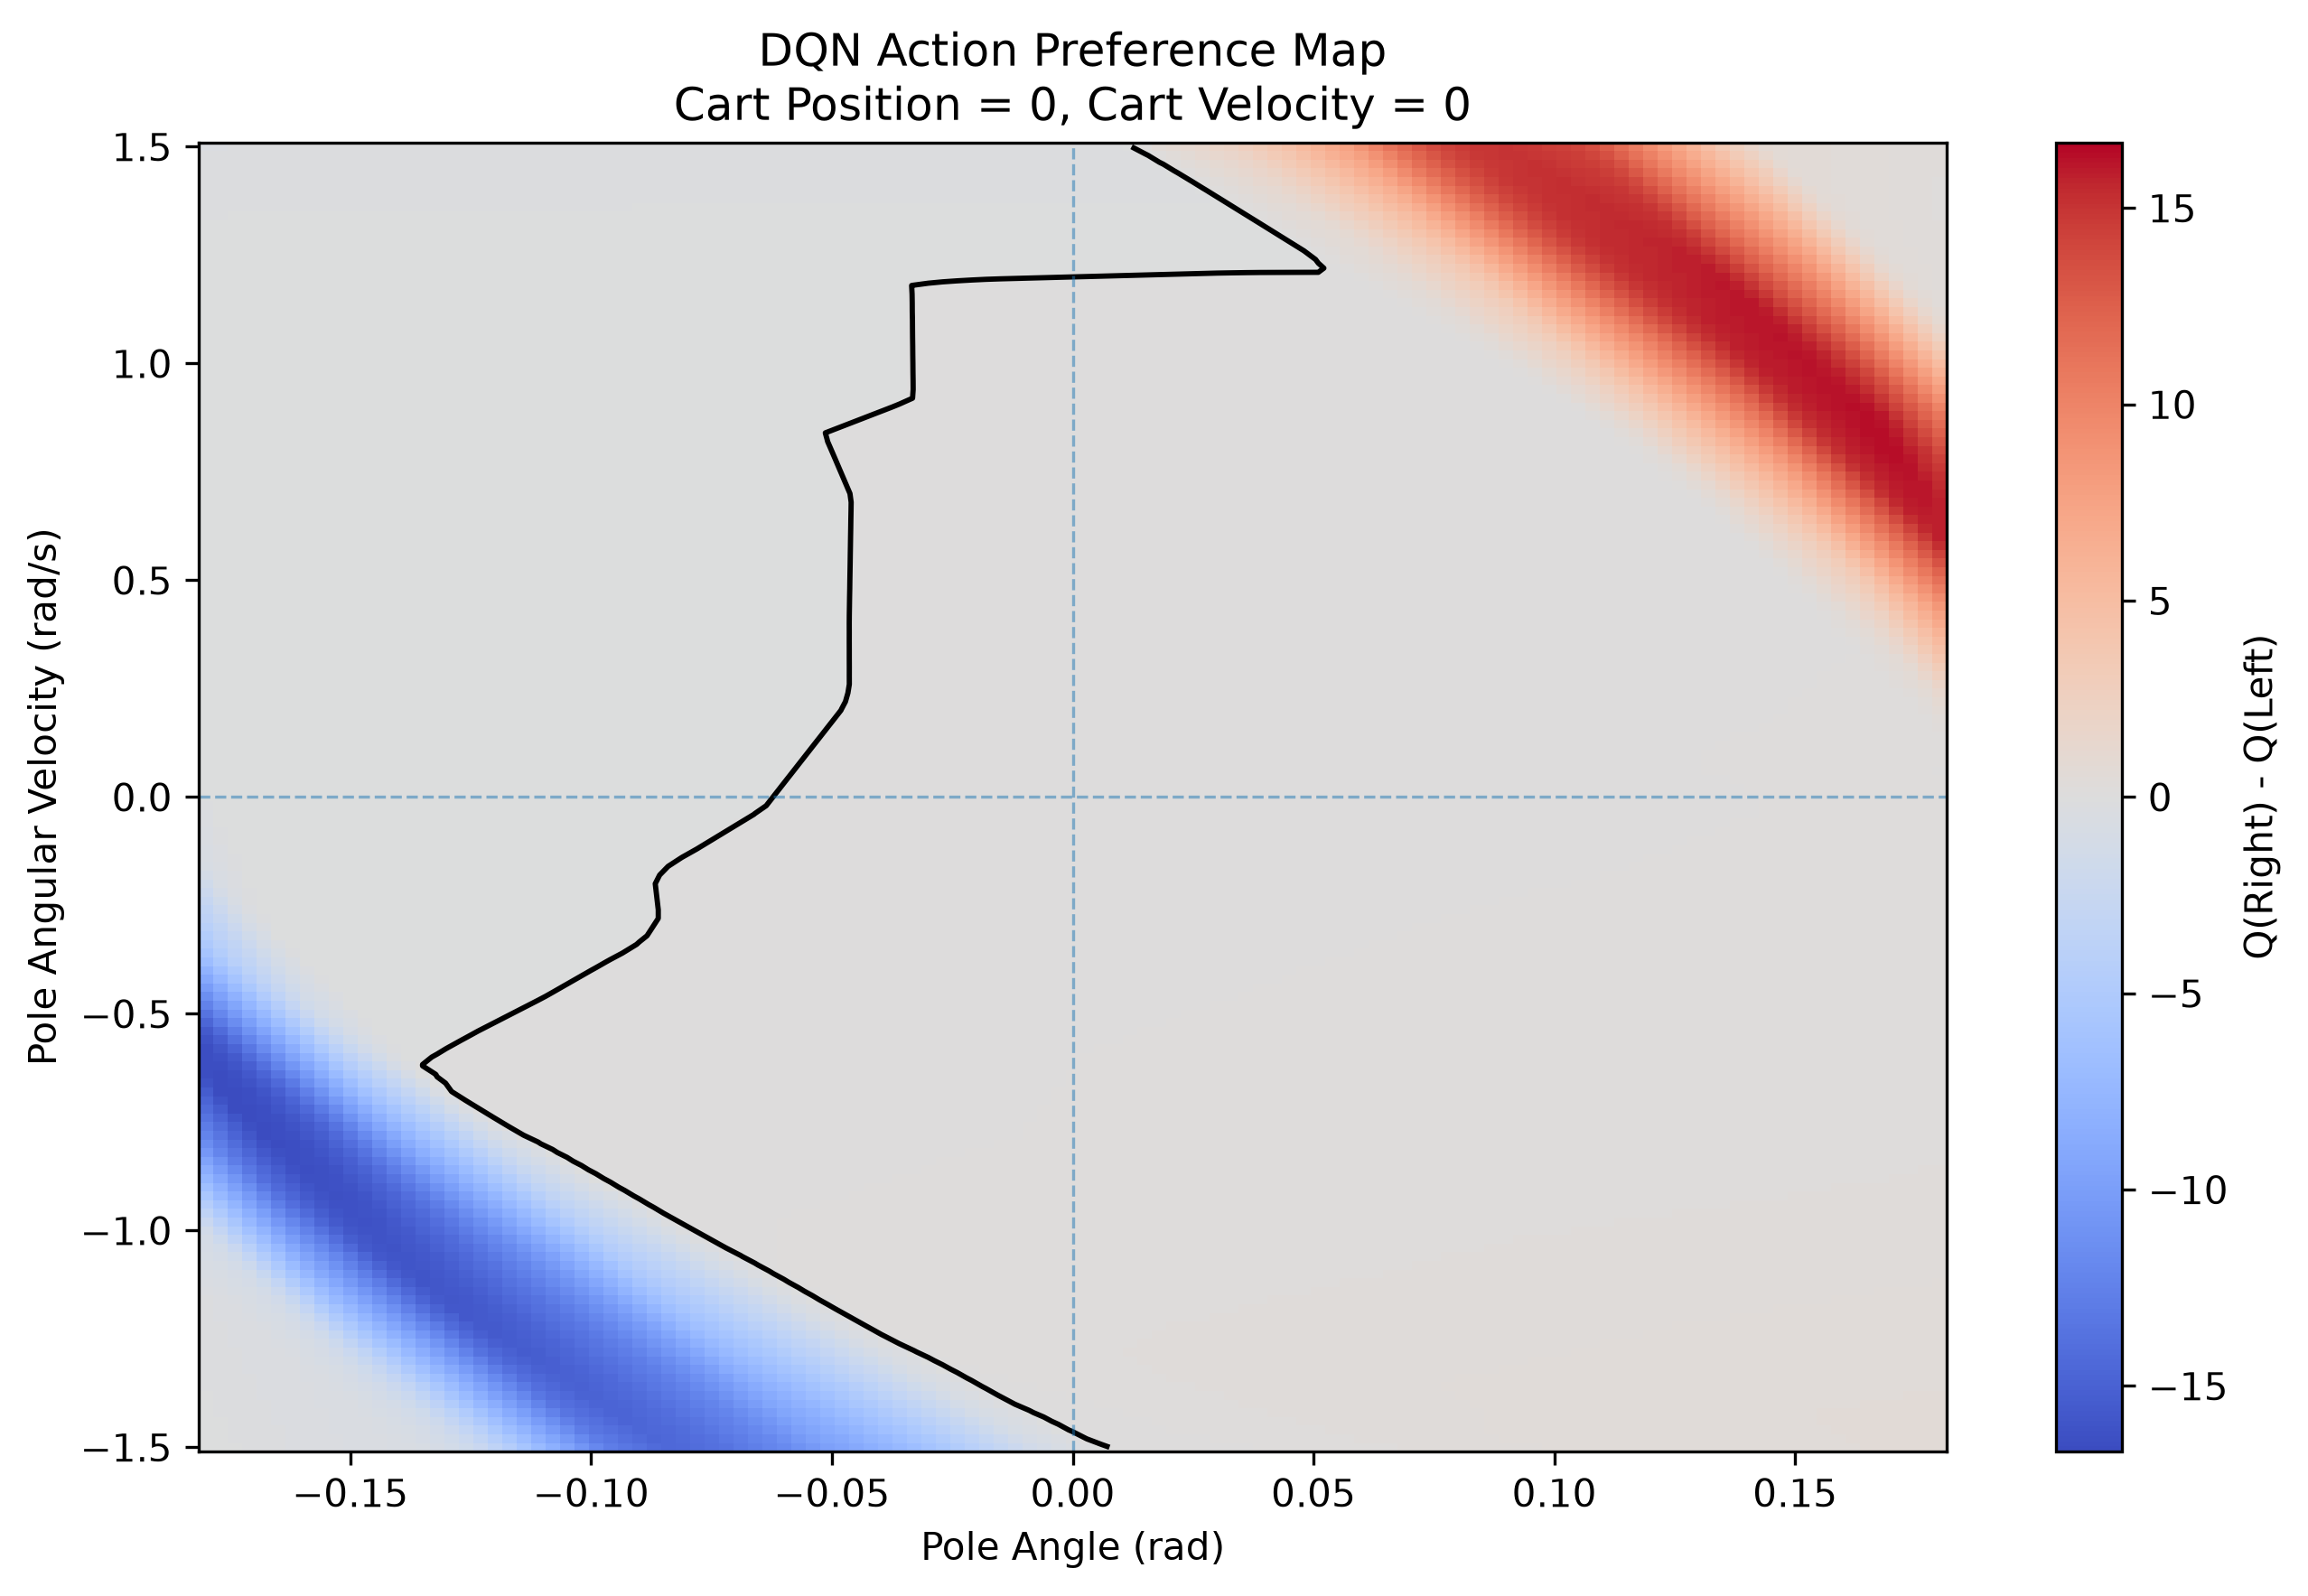

Image displayed from: C:\Users\24298\Downloads\results_cartpole_dqn\dqn_action_preference_map.png


In [20]:

# ============================================================
# Step 13.7: Display Saved Q-value Action Preference Map
# No recomputation or plotting
# ============================================================

from pathlib import Path
from IPython.display import display, Image, Markdown

RESULTS_DIR = Path("results_cartpole_dqn")

image_path = RESULTS_DIR / "dqn_action_preference_map.png"

if not image_path.exists():
    raise FileNotFoundError(
        f"Action preference map not found: {image_path.resolve()}"
    )

display(Markdown("### DQN Action Preference Map"))

display(
    Image(
        filename=str(image_path),
        width=900
    )
)

print("Image displayed from:", image_path.resolve())
